# Commute emissions by mode with US factors: New York and Houston

The commuting flows of LODES between census tracts, routed from the housing-weighted home point
to the jobs-weighted work point of 05.7 by transit, car, bicycle, e-bike and on foot, with the
life-cycle CO₂e of each commute attached by cafein **at the US-specific factors of
`factors/us-v4/`** (version v4, 2026-11-20, DRAFT) instead of the shipped Finnish/ITF factors
of 05.9. Everything else, flows, routing points, departure, caps and reporting, is as in 05.9.

| Step | What we do |
|---|---|
| 1. Parameters | The areas, the routing settings of 05.9, and the factor files and version in force |
| 2. Factors in force | The street rows per area and the transit rows by GTFS route type, with the source row of each |
| 3. Transit agencies | The GTFS agencies of each area's feeds matched to the National Transit Database agencies of the factor file, one factor row per matched route, and the coverage of the match |
| 4. Routing with emissions | One cost matrix per area and mode, streamed to the run's matrix folders |
| 5. Check | The factor each matrix actually carried, read back from the shards |
| 6. Commute table | Every commuting flow with its minutes, distance and grams per mode, saved long per area, with the worker-weighted summary and the comparison with the earlier runs |
| 7. Distribution | The worker-weighted distribution of one-way grams per mode |
| 8. Maps | Weekly commuting CO₂e by home tract, one figure per mode, saved as PNG |

**What the US factors change.** The car is a new 2022 small SUV, cradle to grave (Argonne GREET),
plus US road infrastructure: 287.4 g per vehicle-km, divided by the US commute occupancy of 1.19
persons, 241.5 g per passenger-km. The electric car takes the metro's eGRID 2023 subregion
(NYCW for New York, ERCT for Houston). Transit rows come from the 2024 National Transit Database
fuel, electricity and passenger-km, with ITF vehicle and infrastructure components, resolved in
the order the parameter document prescribes: the agency's own row for the leg's mode where the
GTFS agency is matched to an NTD agency, else the metro row by route type, else the national
`US` row. Walking, bicycle and e-bike are unchanged.

**Run tags.** The street matrices depend only on the car row and are shared across transit
refinements (`matrices-emissions-us-v4`); the transit matrix carries the run tag. The earlier
run of this notebook (job 3273505, `us-v4`) used the metro rows for every agency; this run
(`us-v4-agency`) adds the agency rows.

In [1]:
import json
import re
import time
import zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cafein
from cafein import StreetNetwork, TransportNetwork, TravelCostMatrix, TravelTimeMatrix
from cafein._streaming import read_shards
from cafein.emissions import load_factors, load_street_factors, street_factors, trip_factors, _per_person_factor

print("cafein", cafein.__version__)

cafein 0.31.0


## 1. Parameters

The only cell to edit for another city. The routing settings are those of 05.9; the emission
factors are read from the factor folder, whose version is recorded in the parameter table.

In [2]:
YEAR = 2023
RESULTS = Path("/scratch/project_2010423/carbon-advantage/commuting")
GTFS = Path("/scratch/project_2010423/data/gtfs")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

# The factor set in force: the folder, its version, and the matrix folders that go with it.
FACTORS_DIR = Path("factors/us-v4")
US_PARAMETERS = json.loads((FACTORS_DIR / "us_parameters.json").read_text())
FACTOR_VERSION = f"{US_PARAMETERS['version']} ({US_PARAMETERS['date']}, {US_PARAMETERS['status']})"
RUN_TAG = "us-v4-centre"                                       # this run: midday base, the index on the link time of the urban share, parking only at employment-centre workplaces
STREET_MATRIX_FOLDER = "matrices-emissions-us-v4"              # bicycle, e-bike and walk rows unchanged since the us-v4 run: reused
TRANSIT_MATRIX_FOLDER = "matrices-emissions-us-v4-window-parking"   # transit over a 30-minute departure window, unchanged since that run
CAR_FREEFLOW_FOLDER = "matrices-emissions-us-v4-parking3"      # the midday-profile car matrix, routed in the parking3 run and reused; the rush car (reference only) is the us-v4 one, routed without parking
CAR_SPEEDLIMIT_FOLDER = "matrices-emissions-us-v4-freeflow"    # the speed-limit car matrix (no intersection delays), routed in the freeflow run and reused: the link time the index scales
CONGESTION = pd.read_csv(FACTORS_DIR / "congestion_tti_urban_areas.csv").set_index("msa")
URBAN_AREAS = Path("/scratch/project_2010423/data/tiger/tl_2020_us_uac20.zip")   # 2020 Census urban areas, national TIGER/Line file
CAR_FACTORS_MSA = pd.read_csv(FACTORS_DIR / "car_factors_msa.csv").set_index("msa")
TRANSIT_FACTORS_MSA = pd.read_csv(FACTORS_DIR / "transit_factors_msa_route_type.csv")
TRANSIT_FACTORS_AGENCY = pd.read_csv(FACTORS_DIR / "transit_factors_agency_mode.csv")

# One entry per area: its MSA code in the factor files, the results folder of 05.1 to 05.7, the GTFS
# feed folder of 05.3, the street and transit artifacts of 05.3, and the departure routed in 05.3.
AREAS = {
    "New York": {"msa": "NY", "folder": RESULTS / "new-york", "gtfs": GTFS / "new-york", "streets": Path("../networks/new-york-streets.cafein"),
                 "transit": RESULTS / "new-york" / "new-york-transit.cafein", "departure": "2026-11-10 08:30", "utm": "EPSG:32618"},
    "Houston": {"msa": "HOU", "folder": RESULTS / "houston", "gtfs": GTFS / "houston", "streets": RESULTS / "houston" / "houston-streets.cafein",
                "transit": RESULTS / "houston" / "houston-transit.cafein", "departure": "2026-11-10 08:30", "utm": "EPSG:32615"},
    "Chicago": {"msa": "CHI", "folder": RESULTS / "chicago", "gtfs": GTFS / "chicago", "streets": RESULTS / "chicago" / "chicago-streets.cafein",
                "transit": RESULTS / "chicago" / "chicago-transit.cafein", "departure": "2026-11-10 08:30", "utm": "EPSG:32616"},
    "Seattle": {"msa": "SEA", "folder": RESULTS / "seattle", "gtfs": GTFS / "seattle", "streets": RESULTS / "seattle" / "seattle-streets.cafein",
                "transit": RESULTS / "seattle" / "seattle-transit.cafein", "departure": "2026-11-10 08:30", "utm": "EPSG:32610"},
    "Phoenix": {"msa": "PHX", "folder": RESULTS / "phoenix", "gtfs": GTFS / "phoenix", "streets": RESULTS / "phoenix" / "phoenix-streets.cafein",
                "transit": RESULTS / "phoenix" / "phoenix-transit.cafein", "departure": "2026-11-10 08:30", "utm": "EPSG:32612"},
}

# GTFS agency_name (as in the feeds' agency.txt, whitespace collapsed) -> NTD agency of transit_factors_agency_mode.csv.
# An agency absent here, or one whose NTD rows lack the route's mode, takes the metro row by route type.
AGENCY_CROSSWALK = {
    "New York": {
        "MTA New York City Transit": "MTA New York City Transit",
        "MTA Bus Company": "MTA Bus Company",
        "Long Island Rail Road": "MTA Long Island Rail Road",
        "Metro-North Railroad": "MTA Metro-North Railroad",
        "PATH": "Port Authority Trans-Hudson (PATH)",
        "NJ TRANSIT BUS": "New Jersey Transit",
        "NJ TRANSIT RAIL": "New Jersey Transit",
        "Nassau Inter-County Express": "Nassau Inter County Express",
        "Suffolk County Transit - West": "Suffolk County Transit",
        "Suffolk County Transit - East": "Suffolk County Transit",
        "Suffolk County Transit - Central": "Suffolk County Transit",
        "Transport of Rockland (TOR)": "County of Rockland",
        "ShortLine Hudson": "Shortline Transit (Coach USA)",
        "Suburban Transit": "Suburban Transit (Coach USA)",
        "Rockland Coaches": "Rockland Coaches (Coach USA)",
        "Academy Bus": "Academy Lines",
        "Adirondack Trailways": "Adirondack Trailways",
        "Trans-Bridge Lines": "Trans-Bridge Lines",
        "Trans-Bridge Lines, Inc.": "Trans-Bridge Lines",
        "Lakeland Bus Lines Inc.": "Lakeland Bus Lines",
        "New York City Department of Transportation": "NYC DOT Staten Island Ferry",
        "NYC Ferry": "NYC Economic Development Corp. (NYC Ferry)",
        "Seastreak": "SeaStreak",
        "NY Waterway": "NY Waterway (Port Imperial Ferry)",
    },
    "Houston": {
        "Metropolitan Transit Authority of Harris County": "Houston METRO",
        "The Woodlands Township": "The Woodlands Township",
    },
    # GTFS agency names as in the feeds of 05.3.2; the rest (Gary, East Chicago, Valparaiso, the university and building
    # shuttles, Amtrak and the intercity coaches) take the metro row by route type.
    "Chicago": {
        "Chicago Transit Authority": "Chicago Transit Authority",
        "Metra": "Metra",
        "PACE": "Pace Suburban Bus",
        "Northern Indiana Commuter Transportation District": "Northern Indiana Commuter Transportation District (South Shore Line)",
    },
    # King County Metro's feed names itself "Metro Transit" and carries the City of Seattle streetcars, which have no NTD row
    # of their own and take the metro light-rail row; Kitsap, Intercity and Island Transit and the small operators take the
    # metro rows by route type; the monorail (route type 12) has no factor row at all.
    "Seattle": {
        "Metro Transit": "King County Metro",
        "Sound Transit": "Sound Transit",
        "Community Transit": "Community Transit",
        "Pierce Transit": "Pierce Transit",
        "Everett Transit": "Everett Transit",
        "Washington State Ferries": "Washington State Ferries",
    },
    # The Valley Metro feed names one agency for the buses of the City of Phoenix and of Valley Metro RPTA and for the light
    # rail, three NTD agencies: unmapped, so every route takes the metro row by route type (the three pooled).
    "Phoenix": {},
}
# (GTFS agency_name, GTFS route_id) -> NTD agency, for a route that belongs to another NTD reporter than its feed's agency.
ROUTE_OVERRIDES = {
    "New York": {("MTA New York City Transit", "SI"): "MTA Staten Island Railway"},   # the Staten Island Railway rides the subway feed
    "Houston": {},
    "Chicago": {},
    "Seattle": {},
    "Phoenix": {},
}

PARAMETERS = {
    # Transit routing, as in 05.9.
    "access_egress_walk_min": 30,
    "departure_window_min": 30,          # transit minutes: the median travel time over every minute mark of 08:30 to 09:00 (travel-time matrix), as r5py does by default with its 10-min window; the 08:30 journey (cost matrix) supplies distance and grams
    "max_rides": 8,
    "walking_speed_kmph": 3.6,
    # Street routing, as in 05.9.
    "car_profile": "rush",
    "car_parking": False,                # no parking search in the routing: it is added per workplace in the congestion step
    "car_parking_centre_s": 180,         # the parking search where the work tract is an employment centre (job density at or above the threshold below)
    "car_parking_other_s": 0,            # and elsewhere, where parking is easy
    "centre_jobs_per_km2": 10000,        # an employment centre: a work tract with at least this many LODES jobs per km2 (Manhattan's core, downtown Houston, the Medical Center, the Galleria)
    "car_freeflow_profile": "midday",    # the car's base time: cafein's midday profile, intersection delays at their off-peak values and no congestion multiplier; None would be bare speed limits
    "congestion_index": "tti_2024",      # the Travel Time Index column of congestion_tti_urban_areas.csv applied inside the urban area
    "urban_share_points": 41,            # f_urban: the share of this many equally spaced points on the home-work straight line inside the urban area
    "congestion_scales": "link time only",   # the index multiplies the speed-limit (link) time of the urban share; the crossing delays of the base profile are not scaled
    "car_vehicle_class": "ICE",           # the class name the US petrol row is filed under; the row replaces cafein's shipped ICE row
    "car_occupancy": float(CAR_FACTORS_MSA.loc["US", "occupancy"]),   # 1.19 persons per car, US work trips (NHTS 2017)
    "car_bev_scenario": True,             # a BEV column from the driven distance at the metro's eGRID subregion
    "bicycle_speed_kmph": 15.3,
    "e_bike_speed_kmph": 17.4,
    "max_street_time_min": 120,
    # Emissions.
    "components": ["vehicle", "fuel", "infrastructure", "operations"],
    "walk_g_per_km": US_PARAMETERS["walk_g_per_km"],   # 56 g per km, walk mode and the walking legs of transit
    # Reporting.
    "commutes_per_week": 4,
    "output_time_units": "seconds",
}

petrol = CAR_FACTORS_MSA.loc["US"]
parameter_table = pd.DataFrame([
    ("factor set", f"{FACTORS_DIR}/, version {FACTOR_VERSION}", "US_PARAMETERS_FOR_CLAUDE_CODE.md in that folder"),
    ("factor files", "us_parameters.json, car_factors_msa.csv, transit_factors_msa_route_type.csv, transit_factors_agency_mode.csv", "the CSVs as delivered on 2026-11-20"),
    ("run tag", RUN_TAG, "this notebook"),
    ("matrices", f"transit: <area>/{TRANSIT_MATRIX_FOLDER}; free-flow car: <area>/{CAR_FREEFLOW_FOLDER}; rush car, bicycle, e-bike, walk: <area>/{STREET_MATRIX_FOLDER}", "transit from the window run; the free-flow car fresh for this run; the rest shared since us-v4"),
    ("flows", f"LODES {YEAR} JT01 primary jobs, tract to tract, kept tracts of 05.2", "05.1, 05.2"),
    ("routing points", "housing-weighted home point, jobs-weighted work point, empty-block medoid rule", "05.7, validated in 05.8"),
    ("departure", f"Tuesday 08:30 within every feed's validity; transit minutes are the median over every departure minute of the following {PARAMETERS['departure_window_min']} minutes, transit distance and grams come from the 08:30 journey", "05.3; window and median as r5py's defaults; cafein's cost matrix takes no window"),
    ("access and egress walk", f"{PARAMETERS['access_egress_walk_min']} min at each end", "05.9"),
    ("transfer footpaths", "20 min stop to stop, fixed at network build", "05.3"),
    ("walking speed", f"{PARAMETERS['walking_speed_kmph']} km/h", "cafein default"),
    ("car routing", f"base time from the {PARAMETERS['car_freeflow_profile'] or 'free-flow'} profile (intersection delays at their off-peak values, no congestion multiplier), {PARAMETERS['max_street_time_min']} min cap; the {PARAMETERS['car_profile']} profile with intersection delays routed only as a reference column", "05.3; congestion and parking added in this notebook"),
    ("car congestion", f"car minutes = base minutes + f_urban x (index - 1) x speed-limit minutes + parking, so the index scales the link time of the urban share and the crossing delays of the base stay; the index is the Urban Mobility Report {PARAMETERS['congestion_index']} of the metro's 2020 Census urban area, f_urban the share of {PARAMETERS['urban_share_points']} points along the home-work straight line inside it; parking {PARAMETERS['car_parking_centre_s'] / 60:.0f} min where the work tract has at least {PARAMETERS['centre_jobs_per_km2']:,} jobs per km2, {PARAMETERS['car_parking_other_s'] / 60:.0f} elsewhere", "CAR_TRAVEL_TIME_INSTRUCTIONS.md, congestion_tti_urban_areas.csv, TIGER/Line UAC20"),
    ("car factor", f"petrol, {petrol['ice_total_g_vkm']} g per vehicle-km (fuel {petrol['ice_vehicle_and_fuel_g_vkm']} cradle-to-grave vehicle and fuel, infrastructure {petrol['ice_infrastructure_g_vkm']} roads), occupancy {PARAMETERS['car_occupancy']}: {petrol['ice_g_per_passenger_km']} g per passenger-km", "Kelly et al. 2024 (GREET, 2022 small SUV); Iyer et al. 2024; NHTS 2017"),
    ("car BEV scenario", "BEV g per passenger-km of the metro's eGRID 2023 subregion applied to the driven distance", "car_factors_msa.csv; Argonne 214 g/mile at the US grid, electricity rescaled by the subregion"),
    ("bicycle, e-bike", "cafein's shipped rows, unchanged", "US parameters section 6"),
    ("walking", f"{PARAMETERS['walk_g_per_km']:.0f} g per km, dietary, walk mode and transit walking legs", "US parameters section 6"),
    ("transit, agency rows", "one row per GTFS route whose agency is matched to an NTD agency, at that agency's row for the route's route_type; several NTD modes of one route_type (MB, CB, RB) pooled by passenger-miles", "transit_factors_agency_mode.csv; crosswalk in this cell"),
    ("transit, fallback rows", "metro row by GTFS route type; the US row where the metro has none; operations 0", "transit_factors_msa_route_type.csv"),
    ("intercity services", "Amtrak (Houston, route type 2) and intercity coaches ride the metro or US row of their route type", "US parameters section 5, note on intercity"),
    ("trolleybus", "route type 11 takes the agency's or metro's trolleybus row, else the US trolleybus row (The Woodlands, Houston)", "US parameters section 5"),
    ("components", ", ".join(PARAMETERS["components"]), "full life cycle"),
    ("weekly figure", f"{PARAMETERS['commutes_per_week']} return commutes per week", "the paper's decent-mobility routine"),
], columns=["parameter", "value used", "source"]).set_index("parameter")
pd.set_option("display.max_colwidth", None)
parameter_table

,value used,source
parameter,,
factor set,"factors/us-v4/, version v4 (2026-11-20, DRAFT)",US_PARAMETERS_FOR_CLAUDE_CODE.md in that folder
factor files,"us_parameters.json, car_factors_msa.csv, transit_factors_msa_route_type.csv, transit_factors_agency_mode.csv",the CSVs as delivered on 2026-11-20
run tag,us-v4-centre,this notebook
matrices,"transit: <area>/matrices-emissions-us-v4-window-parking; free-flow car: <area>/matrices-emissions-us-v4-parking3; rush car, bicycle, e-bike, walk: <area>/matrices-emissions-us-v4",transit from the window run; the free-flow car fresh for this run; the rest shared since us-v4
flows,"LODES 2023 JT01 primary jobs, tract to tract, kept tracts of 05.2","05.1, 05.2"
routing points,"housing-weighted home point, jobs-weighted work point, empty-block medoid rule","05.7, validated in 05.8"
departure,"Tuesday 08:30 within every feed's validity; transit minutes are the median over every departure minute of the following 30 minutes, transit distance and grams come from the 08:30 journey",05.3; window and median as r5py's defaults; cafein's cost matrix takes no window
access and egress walk,30 min at each end,05.9
transfer footpaths,"20 min stop to stop, fixed at network build",05.3


## 2. Emission factors in force

Per area: the street rows cafein will apply, the car row per vehicle-km divided by the occupancy,
and the transit rows by GTFS route type with the metro or national row each comes from. These
route-type rows are the fallback behind the agency rows of step 3. They are layered over
cafein's shipped defaults through `factors=`, so a route type absent from both the metro and the
US table would still fall back to the shipped Finnish value; the US table covers every base type
the two feed sets contain (0, 1, 2, 3, 4 and 11).

In [3]:
components = PARAMETERS["components"]
ROUTE_TYPE_NAMES = {0: "tram, light rail", 1: "subway, metro", 2: "rail", 3: "bus", 4: "ferry", 5: "cable tram", 11: "trolleybus", 12: "monorail, guideway"}

# The US petrol car as one street-factor row per vehicle-km, filed under the class the car query asks for.
CAR_FACTORS = pd.DataFrame([{
    "street_mode": "car", "vehicle_class": PARAMETERS["car_vehicle_class"], "service_model": "private",
    "vehicle": 0.0, "fuel": petrol["ice_vehicle_and_fuel_g_vkm"], "infrastructure": petrol["ice_infrastructure_g_vkm"], "operations": 0.0,
    "basis": "vehicle_km",
}])
load_street_factors(CAR_FACTORS)   # validates the shape


def route_type_rows(msa):
    # The metro's rows by route type, completed with the US rows for the types it lacks.
    own = TRANSIT_FACTORS_MSA.loc[TRANSIT_FACTORS_MSA["msa"] == msa]
    national = TRANSIT_FACTORS_MSA.loc[(TRANSIT_FACTORS_MSA["msa"] == "US") & ~TRANSIT_FACTORS_MSA["route_type"].isin(own["route_type"])]
    table = pd.concat([own, national], ignore_index=True).sort_values("route_type")
    table["mode"] = table["route_type"].map(ROUTE_TYPE_NAMES)
    table["row from"] = table["msa"]
    table["basis"] = "passenger_km"
    return table[["route_type", "mode", "ntd_modes_pooled"] + components + ["basis", "row from"]].reset_index(drop=True)


SHIPPED = street_factors().set_index(["street_mode", "vehicle_class", "service_model"])
ROUTE_TYPE_FACTORS, CAR_BEV_G_PER_M, CAR_ICE_G_PER_M = {}, {}, {}
for area, spec in AREAS.items():
    car_row = CAR_FACTORS_MSA.loc[spec["msa"]]
    CAR_ICE_G_PER_M[area] = _per_person_factor("car", CAR_FACTORS, components, PARAMETERS["car_occupancy"], vehicle_class=PARAMETERS["car_vehicle_class"]) / 1000
    CAR_BEV_G_PER_M[area] = car_row["bev_g_per_passenger_km"] / 1000
    street = pd.DataFrame([
        {"mode": "walk", "vehicle": 0.0, "fuel": PARAMETERS["walk_g_per_km"], "infrastructure": 0.0, "operations": 0.0, "basis": "passenger_km"},
        {"mode": "bicycle", **SHIPPED.loc[("bicycle", "conventional", "private")][components + ["basis"]].to_dict()},
        {"mode": "e_bike", **SHIPPED.loc[("bicycle", "e_bike", "private")][components + ["basis"]].to_dict()},
        {"mode": "car (petrol, US)", **CAR_FACTORS.iloc[0][components + ["basis"]].to_dict()},
        {"mode": f"car (BEV scenario, {car_row['egrid_subregion']} {car_row['grid_g_per_kwh']:.0f} g/kWh)", "vehicle": car_row["bev_vehicle_g_vkm"], "fuel": car_row["bev_fuel_g_vkm"],
         "infrastructure": car_row["bev_infrastructure_g_vkm"], "operations": 0.0, "basis": "vehicle_km"},
    ]).set_index("mode")
    street["total"] = street[components].sum(axis=1)
    street["per person-km at the occupancy used"] = np.where(street["basis"] == "vehicle_km", street["total"] / PARAMETERS["car_occupancy"], street["total"])
    print(f"{area} ({spec['msa']}), street modes, g CO2e per km; the car query divides vehicle-km rows by {PARAMETERS['car_occupancy']}:")
    display(street.round(1))
    print(f"  car per passenger-km as cafein resolves it: {CAR_ICE_G_PER_M[area] * 1000:.1f}; BEV scenario {CAR_BEV_G_PER_M[area] * 1000:.1f} "
          f"(BEV/ICE {car_row['bev_over_ice']:.3f})")

    table = route_type_rows(spec["msa"])
    ROUTE_TYPE_FACTORS[area] = table
    table = table.copy()
    table["total"] = table[components].sum(axis=1)
    print(f"{area}, transit fallback rows, g CO2e per passenger-km by GTFS route type:")
    display(table.set_index(["route_type", "mode"])[["ntd_modes_pooled"] + components + ["total", "row from"]].round(1))

WALK_G_PER_M = PARAMETERS["walk_g_per_km"] / 1000

New York (NY), street modes, g CO2e per km; the car query divides vehicle-km rows by 1.19:


,vehicle,fuel,infrastructure,operations,basis,total,per person-km at the occupancy used
mode,,,,,,,
walk,0.0,56.0,0.0,0.0,passenger_km,56.0,56.0
bicycle,7.0,21.0,9.0,0.0,passenger_km,37.0,37.0
e_bike,13.0,3.0,9.0,0.0,passenger_km,25.0,25.0
"car (petrol, US)",0.0,274.0,13.4,0.0,vehicle_km,287.4,241.5
"car (BEV scenario, NYCW 507 g/kWh)",40.4,117.2,13.4,0.0,vehicle_km,171.0,143.7


  car per passenger-km as cafein resolves it: 241.5; BEV scenario 143.7 (BEV/ICE 0.595)
New York, transit fallback rows, g CO2e per passenger-km by GTFS route type:


,,ntd_modes_pooled,vehicle,fuel,infrastructure,operations,total,row from
route_type,mode,,,,,,,
0,"tram, light rail",LR,9.4,102.8,51.2,0.0,163.4,NY
1,"subway, metro",HR,1.9,64.8,10.4,0.0,77.1,NY
2,rail,CR+YR,1.9,101.8,10.2,0.0,113.9,NY
3,bus,CB+MB+RB,9.1,185.4,4.1,0.0,198.6,NY
4,ferry,FB,0.0,647.7,0.0,0.0,647.7,NY
11,trolleybus,TB,10.7,116.3,4.8,0.0,131.8,US


Houston (HOU), street modes, g CO2e per km; the car query divides vehicle-km rows by 1.19:


,vehicle,fuel,infrastructure,operations,basis,total,per person-km at the occupancy used
mode,,,,,,,
walk,0.0,56.0,0.0,0.0,passenger_km,56.0,56.0
bicycle,7.0,21.0,9.0,0.0,passenger_km,37.0,37.0
e_bike,13.0,3.0,9.0,0.0,passenger_km,25.0,25.0
"car (petrol, US)",0.0,274.0,13.4,0.0,vehicle_km,287.4,241.5
"car (BEV scenario, ERCT 389 g/kWh)",40.4,90.0,13.4,0.0,vehicle_km,143.8,120.8


... (10 outputs left out)

Phoenix (PHX), street modes, g CO2e per km; the car query divides vehicle-km rows by 1.19:


,vehicle,fuel,infrastructure,operations,basis,total,per person-km at the occupancy used
mode,,,,,,,
walk,0.0,56.0,0.0,0.0,passenger_km,56.0,56.0
bicycle,7.0,21.0,9.0,0.0,passenger_km,37.0,37.0
e_bike,13.0,3.0,9.0,0.0,passenger_km,25.0,25.0
"car (petrol, US)",0.0,274.0,13.4,0.0,vehicle_km,287.4,241.5
"car (BEV scenario, AZNM 366 g/kWh)",40.4,84.6,13.4,0.0,vehicle_km,138.4,116.3


  car per passenger-km as cafein resolves it: 241.5; BEV scenario 116.2 (BEV/ICE 0.481)
Phoenix, transit fallback rows, g CO2e per passenger-km by GTFS route type:


,,ntd_modes_pooled,vehicle,fuel,infrastructure,operations,total,row from
route_type,mode,,,,,,,
0,"tram, light rail",LR,10.3,108.7,56.1,0.0,175.1,PHX
1,"subway, metro",HR,3.0,77.7,16.3,0.0,97.0,US
2,rail,CR+YR,2.7,138.4,14.8,0.0,155.9,US
3,bus,MB,34.7,566.2,15.6,0.0,616.5,PHX
4,ferry,FB,0.0,739.9,0.0,0.0,739.9,US
11,trolleybus,TB,10.7,116.3,4.8,0.0,131.8,US


## 3. Transit agencies: GTFS to NTD

The parameter document asks for the agency's own NTD row before the metro row. There is no
ready GTFS-to-NTD identifier table, so the match is by agency name: the routes of every feed in
the area's GTFS folder are read with their `agency_name`, the crosswalk of step 1 names the NTD
agency, and the route takes that agency's factor for its `route_type`. Where an NTD agency
reports several modes under one route type (MB, CB and RB are all GTFS bus), the components are
pooled by passenger-miles. Where the agency has no row for the route's mode (NY Waterway's and
NYC Ferry's buses, Metro-North's Hudson Rail Link, The Woodlands trolleybus), the route is
left to the fallback rows.

The network's route ids are joined to the feeds' routes by id and route type; cafein qualifies
an id as `<feed_index>:<id>` when feeds collide, which the join strips. The coverage tables
show, per area, the share of the network's trips resolved by an agency row, the GTFS agencies
that stay on the fallback rows, and the NTD agencies of the factor file that appear in no feed.
Trips are then resolved through cafein's own ladder to confirm the rows land.

In [4]:
def squeeze(name):
    return re.sub(r"\s+", " ", str(name)).strip()


def gtfs_routes(gtfs_dir):
    # Every route of every feed in the folder with its agency name, as cafein saw them when the network was built.
    rows = []
    for path in sorted(Path(gtfs_dir).glob("*.zip")):
        with zipfile.ZipFile(path) as archive:
            names = set(archive.namelist())
            if "routes.txt" not in names or "agency.txt" not in names:
                continue
            agencies = pd.read_csv(archive.open("agency.txt"), dtype=str, encoding="utf-8-sig").fillna("")
            routes = pd.read_csv(archive.open("routes.txt"), dtype=str, encoding="utf-8-sig").fillna("")
        if "agency_id" not in agencies.columns:
            agencies["agency_id"] = ""
        if "agency_id" not in routes.columns or len(agencies) == 1:
            routes["agency_id"] = agencies["agency_id"].iloc[0]
        agencies["agency_id"] = agencies["agency_id"].str.strip()
        routes["agency_id"] = routes["agency_id"].str.strip()
        names = dict(zip(agencies["agency_id"], agencies["agency_name"].map(squeeze)))
        routes = routes[["route_id", "agency_id", "route_type"]].copy()
        routes["agency_name"] = routes["agency_id"].map(names)
        routes["feed"] = path.name
        rows.append(routes)
    table = pd.concat(rows, ignore_index=True)
    table["route_type"] = pd.to_numeric(table["route_type"], errors="coerce").astype("Int64")
    return table


def agency_rows(msa):
    # One row per (NTD agency, route_type): the agency's modes under that GTFS type pooled by passenger-miles.
    rows = TRANSIT_FACTORS_AGENCY.loc[TRANSIT_FACTORS_AGENCY["msa"] == msa].copy()
    weight = rows["passenger_miles_million"].astype(float)
    pooled = []
    for (agency, route_type), group in rows.groupby(["agency", "route_type"]):
        w = weight.loc[group.index]
        pooled.append({"agency": agency, "route_type": int(route_type), "ntd_modes": "+".join(sorted(group["ntd_mode"])),
                       **{c: float(np.average(group[c], weights=w)) for c in components}, "passenger_miles_million": float(w.sum())})
    return pd.DataFrame(pooled)


QUALIFIED = re.compile(r"^\d+:")
TRANSIT_FACTORS, coverage, agency_tables = {}, [], {}
for area, spec in AREAS.items():
    feeds = gtfs_routes(spec["gtfs"])
    crosswalk = {squeeze(k): v for k, v in AGENCY_CROSSWALK[area].items()}
    feeds["ntd_agency"] = feeds["agency_name"].map(crosswalk).astype(object)   # object even when nothing maps (an empty crosswalk), so the merge below accepts it
    for (agency_name, route_id), ntd_agency in ROUTE_OVERRIDES[area].items():
        feeds.loc[(feeds["agency_name"] == squeeze(agency_name)) & (feeds["route_id"] == route_id), "ntd_agency"] = ntd_agency
    pooled = agency_rows(spec["msa"])
    feeds = feeds.merge(pooled.rename(columns={"agency": "ntd_agency"}), on=["ntd_agency", "route_type"], how="left")
    feeds["has_agency_row"] = feeds["ntd_agency"].notna() & feeds[components[0]].notna()

    # The network's routes, joined to the feeds' routes by the bare id and route type, the agency id breaking collisions.
    network = TransportNetwork.load(spec["transit"])
    routes = pd.DataFrame(network.routes, columns=["route_id", "agency_id", "route_type"])
    routes["agency_id"] = routes["agency_id"].fillna("").astype(str)
    routes["bare_route_id"] = routes["route_id"].str.replace(QUALIFIED, "", regex=True)
    routes["bare_agency_id"] = routes["agency_id"].str.replace(QUALIFIED, "", regex=True)
    joined = routes.merge(feeds.rename(columns={"route_id": "bare_route_id", "agency_id": "feed_agency_id"}), on=["bare_route_id", "route_type"], how="left")
    same_agency = (joined["feed_agency_id"] == joined["bare_agency_id"]) | joined["feed_agency_id"].isna()
    candidates = joined.loc[same_agency].drop_duplicates(["route_id", "feed"])
    counts = candidates.groupby("route_id").size()
    ambiguous = counts.index[counts > 1]
    matched = candidates.loc[~candidates["route_id"].isin(ambiguous)].set_index("route_id")
    routes = routes.set_index("route_id")
    routes["agency_name"] = matched["agency_name"]
    routes["ntd_agency"] = matched["ntd_agency"].where(matched["has_agency_row"])
    for c in components:
        routes[c] = matched[c].where(matched["has_agency_row"])
    routes["ambiguous"] = routes.index.isin(ambiguous)

    # Trips per route, to weight the coverage the way the network rides it.
    trips = pd.DataFrame(network.trips, columns=["trip_id", "route_id"]).groupby("route_id").size().rename("trips")
    routes = routes.join(trips).fillna({"trips": 0})
    route_rows = routes.loc[routes["ntd_agency"].notna(), components].reset_index()
    route_rows["basis"] = "passenger_km"
    fallback = ROUTE_TYPE_FACTORS[area][["route_type"] + components + ["basis"]]
    factors = pd.concat([fallback, route_rows], ignore_index=True)
    TRANSIT_FACTORS[area] = load_factors(factors)

    # Resolution through cafein's own ladder: the factor every trip will carry.
    resolved = pd.DataFrame(trip_factors(network, TRANSIT_FACTORS[area], components), columns=["trip_id", "factor"])
    resolved = resolved.merge(pd.DataFrame(network.trips, columns=["trip_id", "route_id"]), on="trip_id").merge(
        routes[["route_type", "agency_name", "ntd_agency"]], left_on="route_id", right_index=True, how="left")
    resolved["source"] = np.where(resolved["ntd_agency"].notna(), "agency row", "metro or US row")
    del network

    label = resolved["ntd_agency"].fillna("(fallback: " + resolved["agency_name"].fillna("unmatched id") + ")")
    by_agency = resolved.groupby([label, "route_type"]).agg(
        routes=("route_id", "nunique"), trips=("trip_id", "size"), g_per_pkm=("factor", "first"), g_per_pkm_max=("factor", "max")).reset_index()
    by_agency["source"] = np.where(by_agency["ntd_agency"].str.startswith("(fallback"), "metro or US row", "agency row")
    agency_tables[area] = by_agency.sort_values(["source", "trips"], ascending=[True, False])
    unmatched_ntd = sorted(set(pooled["agency"]) - set(resolved["ntd_agency"].dropna()))
    coverage.append({"area": area, "routes in network": len(routes), "routes with an agency row": int(routes["ntd_agency"].notna().sum()),
                     "routes with an ambiguous id": int(routes["ambiguous"].sum()), "trips": len(resolved),
                     "share of trips on an agency row": float((resolved["source"] == "agency row").mean()),
                     "trips with no factor": int(resolved["factor"].isna().sum()),
                     "NTD agencies of the file not found in the feeds": "; ".join(unmatched_ntd) or "none"})
    print(f"{area}: factor rows passed to cafein: {len(fallback)} by route type + {len(route_rows)} by route")
    display(agency_tables[area].set_index(["source", "ntd_agency", "route_type"]).round(1))

coverage = pd.DataFrame(coverage).set_index("area")
coverage.round(3)

loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

New York: factor rows passed to cafein: 6 by route type + 1170 by route


routes   trips  \
source          ntd_agency                      route_type                   
agency row      MTA New York City Transit       3              253  185108   
                MTA Bus Company                 3               92   45424   
                MTA Metro-North Railroad        2                5   29375   
                New Jersey Transit              3              203   27681   
                Nassau Inter County Express     3               46    7423   
...                                                            ...     ...   
metro or US row (fallback: Ocean Travel)        3                4       8   
                (fallback: Best Bus)            3                4       7   
                (fallback: C&J Bus Lines)       3                1       6   
                (fallback: Concord Coach Lines) 3                2       4   
                (fallback: Superior Tours)      3                1       2   

                                                            g_per_pkm  \
source          ntd_agency                      route_type              
agency row      MTA New York City Transit       3               201.3   
                MTA Bus Company                 3               245.1   
                MTA Metro-North Railroad        2               107.7   
                New Jersey Transit              3               207.4   
                Nassau Inter County Express     3               173.2   
...                                                               ...   
metro or US row (fallback: Ocean Travel)        3               198.6   
                (fallback: Best Bus)            3               198.6   
                (fallback: C&J Bus Lines)       3               198.6   
                (fallback: Concord Coach Lines) 3               198.6   
                (fallback: Superior Tours)      3               198.6   

                                                            g_per_pkm_max  
source          ntd_agency                      route_type                 
agency row      MTA New York City Transit       3                   201.3  
                MTA Bus Company                 3                   245.1  
                MTA Metro-North Railroad        2                   107.7  
                New Jersey Transit              3                   207.4  
                Nassau Inter County Express     3                   173.2  
...                                                                   ...  
metro or US row (fallback: Ocean Travel)        3                   198.6  
                (fallback: Best Bus)            3                   198.6  
                (fallback: C&J Bus Lines)       3                   198.6  
                (fallback: Concord Coach Lines) 3                   198.6  
                (fallback: Superior Tours)      3                   198.6  

[67 rows x 4 columns]

loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

Houston: factor rows passed to cafein: 6 by route type + 141 by route


routes  \
source          ntd_agency                                 route_type           
agency row      Houston METRO                              3              106   
                                                           0                3   
                The Woodlands Township                     3               32   
metro or US row (fallback: Island Transit)                 3               10   
                                                           0                1   
                (fallback: FlixBus-us)                     3                9   
                (fallback: Greyhound-us)                   3               10   
                (fallback: Fort Bend Transit)              3               48   
                (fallback: Connect Transit)                3                4   
                (fallback: Rice)                           3               13   
                (fallback: Univ of Houston)                3                5   
                (fallback: unmatched id)                   3                6   
                (fallback: Amtrak)                         2                1   
                (fallback: The Woodlands Township)         11               1   
                (fallback: Amtrak Chartered Vehicle)       3                1   
                (fallback: University of Houston Downtown) 3                2   

                                                                       trips  \
source          ntd_agency                                 route_type          
agency row      Houston METRO                              3           20157   
                                                           0            1721   
                The Woodlands Township                     3              61   
metro or US row (fallback: Island Transit)                 3            4709   
                                                           0             477   
                (fallback: FlixBus-us)                     3             390   
                (fallback: Greyhound-us)                   3             306   
                (fallback: Fort Bend Transit)              3              84   
                (fallback: Connect Transit)                3              54   
                (fallback: Rice)                           3              19   
                (fallback: Univ of Houston)                3              13   
                (fallback: unmatched id)                   3              12   
                (fallback: Amtrak)                         2               8   
                (fallback: The Woodlands Township)         11              3   
                (fallback: Amtrak Chartered Vehicle)       3               2   
                (fallback: University of Houston Downtown) 3               2   

                                                                       g_per_pkm  \
source          ntd_agency                                 route_type              
agency row      Houston METRO                              3               273.0   
                                                           0               274.4   
                The Woodlands Township                     3               162.3   
metro or US row (fallback: Island Transit)                 3               270.1   
                                                           0               274.4   
                (fallback: FlixBus-us)                     3               270.1   
                (fallback: Greyhound-us)                   3               270.1   
                (fallback: Fort Bend Transit)              3               270.1   
                (fallback: Connect Transit)                3               270.1   
                (fallback: Rice)                           3               270.1   
                (fallback: Univ of Houston)                3               270.1   
                (fallback: unmatched id)                   3               270.

... (7 outputs left out)

loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

Phoenix: factor rows passed to cafein: 6 by route type + 0 by route


routes  \
source          ntd_agency                                           route_type           
metro or US row (fallback: Valley Metro)                             3              108   
                                                                     0                3   
                (fallback: Greyhound-us)                             3               12   
                (fallback: FlixBus-us)                               3                7   
                (fallback: University of Arizona)                    3                1   
                (fallback: Amtrak)                                   2                2   
                (fallback: Limousine Express)                        3                7   
                (fallback: Maricopa Express Transit)                 3                1   
                (fallback: Phoenix Mesa Airport)                     3                2   
                (fallback: Stagecoach Express)                       3                1   
                (fallback: Omnibus Express)                          3                1   
                (fallback: Phoenix Sky Harbor International Airport) 0                1   
                (fallback: Xe Đò Hoàng)                              3                2   

                                                                                 trips  \
source          ntd_agency                                           route_type          
metro or US row (fallback: Valley Metro)                             3           16802   
                                                                     0            1773   
                (fallback: Greyhound-us)                             3             168   
                (fallback: FlixBus-us)                               3             102   
                (fallback: University of Arizona)                    3              26   
                (fallback: Amtrak)                                   2              19   
                (fallback: Limousine Express)                        3               8   
                (fallback: Maricopa Express Transit)                 3               8   
                (fallback: Phoenix Mesa Airport)                     3               8   
                (fallback: Stagecoach Express)                       3               8   
                (fallback: Omnibus Express)                          3               2   
                (fallback: Phoenix Sky Harbor International Airport) 0               2   
                (fallback: Xe Đò Hoàng)                              3               2   

                                                                                 g_per_pkm  \
source          ntd_agency                                           route_type              
metro or US row (fallback: Valley Metro)                             3               616.5   
                                                                     0               175.1   
                (fallback: Greyhound-us)                             3               616.5   
                (fallback: FlixBus-us)                               3               616.5   
                (fallback: University of Arizona)                    3               616.5   
                (fallback: Amtrak)                                   2               155.9   
                (fallback: Limousine Express)                        3               616.5   
                (fallback: Maricopa Express Transit)                 3               616.5   
                (fallback: Phoenix Mesa Airport)                     3               616.5   
                (fallback: Stagecoach Express)                       3               616.5   
                (fallback: Omnibus Express)                          3               616.5   
                (fallback: Phoenix Sky Harbor International Airport) 0               175.1   
                (fallback: Xe Đò Hoàng)         

,routes in network,routes with an agency row,routes with an ambiguous id,trips,share of trips on an agency row,trips with no factor,NTD agencies of the file not found in the feeds
area,,,,,,,
New York,1574,1170,48,423749,0.750,0,County of Rockland; Hampton Jitney; MTA Staten Island Railway; Westchester County Bee-Line
Houston,253,141,6,28018,0.783,0,none
Chicago,412,279,0,75438,0.971,0,none
Seattle,529,66,412,154985,0.093,2010,Pierce Transit
Phoenix,148,0,0,18928,0.000,0,City of Phoenix Public Transit (Valley Metro); Valley Metro RPTA; Valley Metro Rail


## 4. Routing with emissions

One cost matrix per area and mode, from the snapped home points to the snapped work points of
05.7. The transit matrix is streamed to the run's transit folder with the factor table of step 3;
the street matrices live in the shared street folder, so a completed one is reused and only a
missing one is routed. Transit carries the emissions of the ridden legs and the walking metres;
the car carries the US petrol row divided by the occupancy; bicycle, e-bike and walk carry
cafein's rows.

In [5]:
def matrix_complete(path):
    # True when a streamed matrix folder has every shard completed.
    manifest = Path(path) / "manifest.json"
    if not manifest.is_file():
        return False
    shards = json.loads(manifest.read_text())["shards"]
    return bool(shards) and all(shard["completed"] for shard in shards)


def matrix_folder(spec, mode):
    folder = {"transit": TRANSIT_MATRIX_FOLDER, "transit_window": TRANSIT_MATRIX_FOLDER, "car_freeflow": CAR_FREEFLOW_FOLDER, "car_speedlimit": CAR_SPEEDLIMIT_FOLDER}.get(mode, STREET_MATRIX_FOLDER)
    return spec["folder"] / folder / mode


def read_matrix(path):
    # A matrix folder as one frame; under a departure window the travel time comes back as its median column.
    return read_shards(path).rename(columns={"travel_time_p50": "travel_time"})


STREET_QUERIES = {
    "car": {"transport_mode": "car", "intersection_delays": True, "profile": PARAMETERS["car_profile"], "parking": PARAMETERS["car_parking"],
            "vehicle_class": PARAMETERS["car_vehicle_class"], "occupancy": PARAMETERS["car_occupancy"], "factors": CAR_FACTORS},
    "bicycle": {"transport_mode": "bicycle", "speeds": {"bicycle": PARAMETERS["bicycle_speed_kmph"]}},
    "e_bike": {"transport_mode": "e_bike", "speeds": {"e_bike": PARAMETERS["e_bike_speed_kmph"]}},
    "walk": {"transport_mode": "walk", "speeds": {"walk": PARAMETERS["walking_speed_kmph"]}},
}
MODES = ["transit"] + list(STREET_QUERIES)

timings = []
for area, spec in AREAS.items():
    origins = gpd.read_parquet(spec["folder"] / f"tract-points-home-snapped-{YEAR}.parquet")
    destinations = gpd.read_parquet(spec["folder"] / f"tract-points-work-snapped-{YEAR}.parquet")
    print(f"{area}: {len(origins):,} home points, {len(destinations):,} work points")

    # Transit twice: the cost matrix at 08:30 for distances and grams (it takes no departure window), and the
    # travel-time matrix over the departure window for the minutes, the median over every minute mark.
    transit_cost, transit_window = matrix_folder(spec, "transit"), matrix_folder(spec, "transit_window")
    transit_cost.parent.mkdir(exist_ok=True)
    network = None if matrix_complete(transit_cost) and matrix_complete(transit_window) else TransportNetwork.load(spec["transit"])
    if matrix_complete(transit_cost):
        print(f"  transit  complete -> {transit_cost}")
    else:
        started = time.time()
        TravelCostMatrix.to_parquet(network, origins, destinations, departure=spec["departure"], max_rides=PARAMETERS["max_rides"],
                                    max_walking_time=PARAMETERS["access_egress_walk_min"], speeds={"walk": PARAMETERS["walking_speed_kmph"]},
                                    factors=TRANSIT_FACTORS[area], components=components, output_time_units=PARAMETERS["output_time_units"],
                                    output=transit_cost, resume=(transit_cost / "manifest.json").is_file())
        timings.append({"area": area, "mode": "transit", "seconds": time.time() - started})
        print(f"  transit  {time.time() - started:6.0f} s -> {transit_cost}")
    if matrix_complete(transit_window):
        print(f"  transit window complete -> {transit_window}")
    else:
        started = time.time()
        TravelTimeMatrix.to_parquet(network, origins, destinations, departure=spec["departure"], departure_time_window=PARAMETERS["departure_window_min"],
                                    max_rides=PARAMETERS["max_rides"], max_walking_time=PARAMETERS["access_egress_walk_min"], speeds={"walk": PARAMETERS["walking_speed_kmph"]},
                                    output_time_units=PARAMETERS["output_time_units"], output=transit_window, resume=(transit_window / "manifest.json").is_file())
        timings.append({"area": area, "mode": "transit window", "seconds": time.time() - started})
        print(f"  transit window {time.time() - started:6.0f} s -> {transit_window}")
    del network

    streets = None
    for mode, query in STREET_QUERIES.items():
        output = matrix_folder(spec, mode)
        output.parent.mkdir(exist_ok=True)
        if matrix_complete(output):
            print(f"  {mode:8} complete -> {output}")
            continue
        if streets is None:
            streets = StreetNetwork.load(spec["streets"])
        started = time.time()
        TravelCostMatrix.to_parquet(streets, origins, destinations, max_street_time=PARAMETERS["max_street_time_min"], components=components,
                                    output_time_units=PARAMETERS["output_time_units"], output=output, resume=(output / "manifest.json").is_file(), **query)
        timings.append({"area": area, "mode": mode, "seconds": time.time() - started})
        print(f"  {mode:8} {time.time() - started:6.0f} s -> {output}")
    # The car's base time of the congestion step: the profile named in the parameters (midday: the lightest intersection delays, no multiplier), no parking.
    output = matrix_folder(spec, "car_freeflow")
    if matrix_complete(output):
        print(f"  car free-flow complete -> {output}")
    else:
        if streets is None:
            streets = StreetNetwork.load(spec["streets"])
        started = time.time()
        TravelTimeMatrix.to_parquet(streets, origins, destinations, transport_mode="car", intersection_delays=PARAMETERS["car_freeflow_profile"] is not None, profile=PARAMETERS["car_freeflow_profile"],
                                    max_street_time=PARAMETERS["max_street_time_min"], output_time_units=PARAMETERS["output_time_units"],
                                    output=output, resume=(output / "manifest.json").is_file())
        timings.append({"area": area, "mode": "car free-flow", "seconds": time.time() - started})
        print(f"  car free-flow {time.time() - started:6.0f} s -> {output}")
    # The link time the index scales: the speed-limit regime, no intersection delays, no parking.
    output = matrix_folder(spec, "car_speedlimit")
    if matrix_complete(output):
        print(f"  car speed-limit complete -> {output}")
    else:
        if streets is None:
            streets = StreetNetwork.load(spec["streets"])
        started = time.time()
        TravelTimeMatrix.to_parquet(streets, origins, destinations, transport_mode="car", intersection_delays=False,
                                    max_street_time=PARAMETERS["max_street_time_min"], output_time_units=PARAMETERS["output_time_units"],
                                    output=output, resume=(output / "manifest.json").is_file())
        timings.append({"area": area, "mode": "car speed-limit", "seconds": time.time() - started})
        print(f"  car speed-limit {time.time() - started:6.0f} s -> {output}")
    del streets

pd.DataFrame(timings).round(0) if timings else print("every matrix was already complete")

New York: 4,587 home points, 4,588 work points
  transit  complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices-emissions-us-v4-window-parking/transit
  transit window complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices-emissions-us-v4-window-parking/transit_window
  car      complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices-emissions-us-v4/car
  bicycle  complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices-emissions-us-v4/bicycle
  e_bike   complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices-emissions-us-v4/e_bike
  walk     complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices-emissions-us-v4/walk
  car free-flow complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices-emissions-us-v4-parking3/car_freeflow
  car speed-limit complete -> /scratch/project_2010423/carbon-advantage/commutin

  car      complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices-emissions-us-v4/car
  bicycle  complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices-emissions-us-v4/bicycle
  e_bike   complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices-emissions-us-v4/e_bike
  walk     complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices-emissions-us-v4/walk
  car free-flow complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices-emissions-us-v4-parking3/car_freeflow
  car speed-limit complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices-emissions-us-v4-freeflow/car_speedlimit
Chicago: 2,153 home points, 2,153 work points


loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

  transit      13 s -> /scratch/project_2010423/carbon-advantage/commuting/chicago/matrices-emissions-us-v4-window-parking/transit
  transit window complete -> /scratch/project_2010423/carbon-advantage/commuting/chicago/matrices-emissions-us-v4-window-parking/transit_window
  car      complete -> /scratch/project_2010423/carbon-advantage/commuting/chicago/matrices-emissions-us-v4/car
  bicycle  complete -> /scratch/project_2010423/carbon-advantage/commuting/chicago/matrices-emissions-us-v4/bicycle
  e_bike   complete -> /scratch/project_2010423/carbon-advantage/commuting/chicago/matrices-emissions-us-v4/e_bike
  walk     complete -> /scratch/project_2010423/carbon-advantage/commuting/chicago/matrices-emissions-us-v4/walk
  car free-flow complete -> /scratch/project_2010423/carbon-advantage/commuting/chicago/matrices-emissions-us-v4-parking3/car_freeflow
  car speed-limit complete -> /scratch/project_2010423/carbon-advantage/commuting/chicago/matrices-emissions-us-v4-freeflow/car_speedl

loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

/tmp/marinflo/3375742/ipykernel_2424728/498936065.py:44: UserWarning: no emission factor matches route_type(s) [12] for every selected component (route_type 12: vehicle, fuel, infrastructure, operations); journeys riding the affected trips carry no emissions
  TravelCostMatrix.to_parquet(network, origins, destinations, departure=spec["departure"], max_rides=PARAMETERS["max_rides"],


  transit       7 s -> /scratch/project_2010423/carbon-advantage/commuting/seattle/matrices-emissions-us-v4-window-parking/transit
  transit window complete -> /scratch/project_2010423/carbon-advantage/commuting/seattle/matrices-emissions-us-v4-window-parking/transit_window
  car      complete -> /scratch/project_2010423/carbon-advantage/commuting/seattle/matrices-emissions-us-v4/car
  bicycle  complete -> /scratch/project_2010423/carbon-advantage/commuting/seattle/matrices-emissions-us-v4/bicycle
  e_bike   complete -> /scratch/project_2010423/carbon-advantage/commuting/seattle/matrices-emissions-us-v4/e_bike
  walk     complete -> /scratch/project_2010423/carbon-advantage/commuting/seattle/matrices-emissions-us-v4/walk
  car free-flow complete -> /scratch/project_2010423/carbon-advantage/commuting/seattle/matrices-emissions-us-v4-parking3/car_freeflow
  car speed-limit complete -> /scratch/project_2010423/carbon-advantage/commuting/seattle/matrices-emissions-us-v4-freeflow/car_speedl

,area,mode,seconds
0,Chicago,transit,13.0
1,Seattle,transit,7.0


## 5. Check: the factor each matrix carried

Read back from the shards: the grams per kilometre of the car matrix must be the US petrol value
per passenger-km, and the transit matrix must resolve a factor for every itinerary. The transit
grams per ridden kilometre are reported as a distribution over pairs for orientation.

In [6]:
checks = []
for area, spec in AREAS.items():
    car = read_matrix(matrix_folder(spec, "car"))
    driven = car["network_distance_m"] > 0
    per_km = (car.loc[driven, "emissions"] / car.loc[driven, "network_distance_m"] * 1000)
    transit = read_matrix(matrix_folder(spec, "transit"))
    ridden = transit["transit_distance_m"] > 0
    transit_per_km = transit.loc[ridden, "emissions"] / transit.loc[ridden, "transit_distance_m"] * 1000
    checks.append({"area": area,
                   "car g/km min": per_km.min(), "car g/km max": per_km.max(), "car g/km expected": CAR_ICE_G_PER_M[area] * 1000,
                   "transit pairs": int(transit["travel_time"].notna().sum()),
                   "transit pairs with unresolved emissions": int((transit["travel_time"].notna() & transit["emissions"].isna()).sum()),
                   "transit g per ridden km, 5th pct": transit_per_km.quantile(0.05), "median": transit_per_km.median(), "95th pct": transit_per_km.quantile(0.95)})
    del car, transit
pd.DataFrame(checks).set_index("area").round(1)

,car g/km min,car g/km max,car g/km expected,transit pairs,transit pairs with unresolved emissions,"transit g per ridden km, 5th pct",median,95th pct
area,,,,,,,,
New York,241.5,241.5,241.5,18184524,0,77.1,129.7,207.4
Houston,241.5,241.5,241.5,534073,0,273.0,273.0,273.3
Chicago,241.5,241.5,241.5,3050154,0,173.1,295.9,395.9
Seattle,241.5,241.5,241.5,475397,1220,102.4,213.0,244.4
Phoenix,241.5,241.5,241.5,491570,0,335.7,616.5,616.5


## 6. Commute table

Every commuting flow between the kept tracts, with its workers and, per mode, the door-to-door
minutes, the kilometres and the grams CO₂e of one trip, as in 05.9. `car_bev` is the car's trips
with the driven distance at the metro's BEV factor per passenger-km. The table is saved long as
`commute-emissions-<run tag>-<year>.parquet` in the area's folder, beside the Finnish-factor
table of 05.9 and the earlier `us-v4` table, and summarised worker-weighted. The final table sets
the median one-way grams of this run beside those of 05.9 and of the `us-v4` run where those
tables exist.

In [7]:
def weighted_median(values, weights):
    values, weights = np.asarray(values, dtype=float), np.asarray(weights, dtype=float)
    keep = ~np.isnan(values)
    values, weights = values[keep], weights[keep]
    if len(values) == 0:
        return np.nan
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return values[order][np.searchsorted(cumulative, 0.5)]


def read_mode(area, spec, mode):
    # One mode's matrix as minutes, kilometres and grams per trip, keyed by the pair.
    frame = read_matrix(matrix_folder(spec, "car" if mode == "car_bev" else mode))
    out = pd.DataFrame({"from_id": frame["from_id"].astype(str), "to_id": frame["to_id"].astype(str), "minutes": frame["travel_time"] / 60})
    if mode == "transit":
        out["km"] = (frame["transit_distance_m"] + frame["walk_distance_m"]) / 1000
        out["grams"] = frame["emissions"] + frame["walk_distance_m"] * WALK_G_PER_M
        out["transit_grams_unresolved"] = frame["emissions"].isna()
        # The minutes are the median over the departure window, from the travel-time matrix; only pairs with both matrices are kept.
        window = read_matrix(matrix_folder(spec, "transit_window"))
        window = pd.DataFrame({"from_id": window["from_id"].astype(str), "to_id": window["to_id"].astype(str), "minutes": window["travel_time"] / 60})
        at_departure = len(out)
        out = out.drop(columns="minutes").merge(window, on=["from_id", "to_id"], how="inner")
        print(f"  {area} transit: {at_departure:,} pairs reached at 08:30, {len(window):,} with a window median, {len(out):,} kept with both")
    else:
        out["km"] = frame["network_distance_m"] / 1000
        out["grams"] = frame["network_distance_m"] * WALK_G_PER_M if mode == "walk" else frame["emissions"]
        if mode == "car_bev":
            out["grams"] = frame["network_distance_m"] * CAR_BEV_G_PER_M[area]
        if mode in ("car", "car_bev"):
            # The midday-profile time of the same pair, the uncongested reference of the congestion step.
            freeflow = read_matrix(matrix_folder(spec, "car_freeflow"))
            freeflow = pd.DataFrame({"from_id": freeflow["from_id"].astype(str), "to_id": freeflow["to_id"].astype(str), "minutes_freeflow": freeflow["travel_time"] / 60})
            out = out.merge(freeflow, on=["from_id", "to_id"], how="left")
            links = read_matrix(matrix_folder(spec, "car_speedlimit"))
            links = pd.DataFrame({"from_id": links["from_id"].astype(str), "to_id": links["to_id"].astype(str), "minutes_speedlimit": links["travel_time"] / 60})
            out = out.merge(links, on=["from_id", "to_id"], how="left")
    return out


def urban_area(spec):
    # The metro's main 2020 Census urban area, the one polygon whose name starts with the text of the congestion table.
    prefix = CONGESTION.loc[spec["msa"], "census_urban_area_2020_name_to_match"]
    matches = gpd.read_file(URBAN_AREAS, where=f"NAME20 LIKE '{prefix}%'")
    if len(matches) != 1:
        raise ValueError(f"{prefix!r} matches {len(matches)} urban areas: {matches['NAME20'].tolist()}")
    print(f"  urban area: {matches['NAME20'].iloc[0]}")
    return matches.to_crs(spec["utm"]).geometry.iloc[0]


def urban_shares(spec, pairs):
    # f_urban per pair: the share of equally spaced points on the straight line from the home point to the work point inside the urban area.
    import shapely
    polygon = urban_area(spec)
    shapely.prepare(polygon)
    homes = gpd.read_parquet(spec["folder"] / f"tract-points-home-snapped-{YEAR}.parquet").to_crs(spec["utm"]).set_index(gpd.read_parquet(spec["folder"] / f"tract-points-home-snapped-{YEAR}.parquet")["id"].astype(str))
    works = gpd.read_parquet(spec["folder"] / f"tract-points-work-snapped-{YEAR}.parquet").to_crs(spec["utm"]).set_index(gpd.read_parquet(spec["folder"] / f"tract-points-work-snapped-{YEAR}.parquet")["id"].astype(str))
    start = np.column_stack([homes.geometry.x.reindex(pairs["from_id"]).to_numpy(), homes.geometry.y.reindex(pairs["from_id"]).to_numpy()])
    end = np.column_stack([works.geometry.x.reindex(pairs["to_id"]).to_numpy(), works.geometry.y.reindex(pairs["to_id"]).to_numpy()])
    inside = np.zeros(len(pairs))
    for t in np.linspace(0, 1, PARAMETERS["urban_share_points"]):
        point = start + t * (end - start)
        inside += shapely.contains_xy(polygon, point[:, 0], point[:, 1])
    return pd.DataFrame({"from_id": pairs["from_id"].to_numpy(), "to_id": pairs["to_id"].to_numpy(), "f_urban": inside / PARAMETERS["urban_share_points"]})


def employment_centres(spec, flows):
    # The work tracts that count as employment centres: LODES jobs per km2 of the kept tract polygon at or above the threshold.
    jobs = flows.groupby("to_id")["workers"].sum()
    tracts = gpd.read_parquet(spec["folder"] / f"tracts-kept-{YEAR}.parquet")[["tract", "geometry"]].to_crs(spec["utm"])
    density = jobs.reindex(tracts["tract"].astype(str).to_numpy()).fillna(0).to_numpy() / (tracts.geometry.area.to_numpy() / 1e6)
    centres = set(tracts["tract"].astype(str)[density >= PARAMETERS["centre_jobs_per_km2"]])
    print(f"  employment centres: {len(centres):,} tracts hold {jobs.reindex(list(centres)).sum() / jobs.sum():.1%} of the jobs")
    return centres


def congested(joined, spec, centres):
    # The car time of the congestion step: the base (midday-profile) time, plus the index's uplift on the link (speed-limit) time of the urban share
    # of the trip, plus a parking search where the work tract is an employment centre. The crossing delays of the base are not scaled: the index
    # describes slower driving, not more crossings. The rush-profile time stays beside it as cafein's own peak estimate, for reference only.
    index = CONGESTION.loc[spec["msa"], PARAMETERS["congestion_index"]]
    joined["minutes_rush"] = joined["minutes"]
    base = joined["minutes_freeflow"].fillna(joined["minutes_rush"])
    links = joined["minutes_speedlimit"].fillna(base)
    joined["work_in_centre"] = joined["to_id"].isin(centres)
    parking = np.where(joined["work_in_centre"], PARAMETERS["car_parking_centre_s"], PARAMETERS["car_parking_other_s"]) / 60
    joined["minutes"] = base + joined["f_urban"] * (index - 1) * links + parking
    return joined


def congestion_report(area, spec, car, transit_minutes):
    wt = car["workers"].to_numpy(dtype=float)
    km = car["km"].fillna(0).to_numpy()
    f_urban = car["f_urban"].to_numpy()
    both = car["minutes"].notna().to_numpy() & ~np.isnan(transit_minutes)
    share = lambda mask, weights: weights[mask].sum() / weights.sum()
    return {"area": area, "tti": CONGESTION.loc[spec["msa"], PARAMETERS["congestion_index"]],
            "median rush / base of cafein": weighted_median(car["minutes_rush"] / car["minutes_freeflow"], wt),
            "commuters f=1": share(f_urban == 1, wt), "commuters 0<f<1": share((f_urban > 0) & (f_urban < 1), wt), "commuters f=0": share(f_urban == 0, wt),
            "car-km f=1": share(f_urban == 1, wt * km), "car-km 0<f<1": share((f_urban > 0) & (f_urban < 1), wt * km), "car-km f=0": share(f_urban == 0, wt * km),
            "commuters working in an employment centre": share(car["work_in_centre"].to_numpy(), wt),
            "median car min, speed-limit links": weighted_median(car["minutes_speedlimit"], wt),
            "median car min, base profile": weighted_median(car["minutes_freeflow"], wt),
            "median car min, cafein rush": weighted_median(car["minutes_rush"], wt),
            "median car min, final": weighted_median(car["minutes"], wt),
            "transit as fast as the car, at cafein rush": wt[both & (transit_minutes <= car["minutes_rush"].to_numpy())].sum() / wt[both].sum(),
            "transit as fast as the car, final": wt[both & (transit_minutes <= car["minutes"].to_numpy())].sum() / wt[both].sum()}


REPORTED_MODES = ["transit", "car"] + (["car_bev"] if PARAMETERS["car_bev_scenario"] else []) + ["bicycle", "e_bike", "walk"]

commutes = {}
rows, congestion_rows = [], []
for area, spec in AREAS.items():
    flows = pd.read_parquet(spec["folder"] / f"tract-od-{YEAR}.parquet")
    flows["from_id"], flows["to_id"] = flows["from_id"].astype(str), flows["to_id"].astype(str)
    origins = set(gpd.read_parquet(spec["folder"] / f"tract-points-home-snapped-{YEAR}.parquet")["id"].astype(str))
    destinations = set(gpd.read_parquet(spec["folder"] / f"tract-points-work-snapped-{YEAR}.parquet")["id"].astype(str))
    flows = flows.loc[flows["from_id"].isin(origins) & flows["to_id"].isin(destinations), ["from_id", "to_id", "workers"]]
    parts, shares, centres = [], None, employment_centres(spec, flows)
    for mode in REPORTED_MODES:
        matrix = read_mode(area, spec, mode)
        joined = flows.merge(matrix, on=["from_id", "to_id"], how="left")
        joined.insert(3, "mode", mode)
        if mode in ("car", "car_bev"):
            if shares is None:
                shares = urban_shares(spec, flows)
            joined = congested(joined.merge(shares, on=["from_id", "to_id"], how="left"), spec, centres)
            if mode == "car":
                assert len(parts[0]) == len(joined) and REPORTED_MODES[0] == "transit"
                congestion_rows.append(congestion_report(area, spec, joined, parts[0]["minutes"].to_numpy()))
        parts.append(joined)
        reached = joined["minutes"].notna()
        row = {"area": area, "mode": mode, "commuters": flows["workers"].sum(),
               "commuters with an itinerary": joined.loc[reached, "workers"].sum(),
               "share with an itinerary": joined.loc[reached, "workers"].sum() / flows["workers"].sum(),
               "median minutes": weighted_median(joined["minutes"], joined["workers"]),
               "median km": weighted_median(joined["km"], joined["workers"]),
               "median g, one way": weighted_median(joined["grams"], joined["workers"])}
        row["median kg, return trip"] = 2 * row["median g, one way"] / 1000
        row["median kg per week"] = PARAMETERS["commutes_per_week"] * row["median kg, return trip"]
        if mode == "transit":
            row["itineraries with an unresolved factor"] = int(joined.loc[reached, "transit_grams_unresolved"].sum())
        rows.append(row)
    table = pd.concat(parts, ignore_index=True)
    table.attrs = {"factor_set": str(FACTORS_DIR), "factor_version": FACTOR_VERSION, "run_tag": RUN_TAG}
    out = spec["folder"] / f"commute-emissions-{RUN_TAG}-{YEAR}.parquet"
    table.to_parquet(out, index=False)
    commutes[area] = table
    print(f"{area}: {len(flows):,} flows, {flows['workers'].sum():,} commuters, saved {out}")

summary = pd.DataFrame(rows).set_index(["area", "mode"])
print(f"worker-weighted summary of one commute per mode at the US factors {FACTOR_VERSION}, run {RUN_TAG}; grams and kilograms are CO2e over the full life cycle:")
display(summary.round({"share with an itinerary": 3, "median minutes": 1, "median km": 1, "median g, one way": 0, "median kg, return trip": 2, "median kg per week": 1}))
print("the congestion step, per metro:")
display(pd.DataFrame(congestion_rows).set_index("area").T.round(3))

# Beside the earlier runs, where their tables exist.
EARLIER = {"Finnish factors (05.9)": f"commute-emissions-{YEAR}.parquet", "US v4, metro rows only": f"commute-emissions-us-v4-{YEAR}.parquet"}
comparison = []
for area, spec in AREAS.items():
    for mode in REPORTED_MODES:
        row = {"area": area, "mode": mode}
        for label, name in EARLIER.items():
            path = spec["folder"] / name
            if path.exists():
                earlier = pd.read_parquet(path, columns=["mode", "workers", "grams"])
                earlier = earlier.loc[earlier["mode"] == mode]
                row[f"median g one way, {label}"] = weighted_median(earlier["grams"], earlier["workers"])
        row[f"median g one way, {RUN_TAG}"] = summary.loc[(area, mode), "median g, one way"]
        comparison.append(row)
comparison = pd.DataFrame(comparison).set_index(["area", "mode"])
comparison.round(0)

  employment centres: 313 tracts hold 38.7% of the jobs


  New York transit: 18,184,524 pairs reached at 08:30, 18,179,084 with a window median, 18,179,084 kept with both


  urban area: New York--Jersey City--Newark, NY--NJ


New York: 2,408,018 flows, 6,708,469 commuters, saved /scratch/project_2010423/carbon-advantage/commuting/new-york/commute-emissions-us-v4-centre-2023.parquet
  employment centres: 11 tracts hold 14.1% of the jobs


  Houston transit: 534,073 pairs reached at 08:30, 534,073 with a window median, 534,073 kept with both


  urban area: Houston, TX


... (11 outputs left out)

commuters  commuters with an itinerary  \
area     mode                                              
New York transit    6708469                      6066192   
         car        6708469                      6630009   
         car_bev    6708469                      6630009   
         bicycle    6708469                      5017984   
         e_bike     6708469                      5282030   
         walk       6708469                      1784120   
Houston  transit    2114670                       664895   
         car        2114670                      2106212   
         car_bev    2114670                      2106212   
         bicycle    2114670                      1372017   
         e_bike     2114670                      1511267   
         walk       2114670                       281460   
Chicago  transit    3423828                      2320540   
         car        3423828                      3394424   
         car_bev    3423828                      3394424   
         bicycle    3423828                      2438745   
         e_bike     3423828                      2606544   
         walk       3423828                       677633   
Seattle  transit    1531980                      1291844   
         car        1531980                      1520697   
         car_bev    1531980                      1520697   
         bicycle    1531980                      1158896   
         e_bike     1531980                      1233799   
         walk       1531980                       293738   
Phoenix  transit    1748052                      1092175   
         car        1748052                      1728464   
         car_bev    1748052                      1728464   
         bicycle    1748052                      1187617   
         e_bike     1748052                      1300675   
         walk       1748052                       221886   

                  share with an itinerary  median minutes  median km  \
area     mode                                                          
New York transit                    0.904            65.7       17.2   
         car                        0.988            33.4       17.2   
         car_bev                    0.988            33.4       17.2   
         bicycle                    0.748            42.0       10.6   
         e_bike                     0.787            39.1       11.2   
         walk                       0.266            60.2        3.6   
Houston  transit                    0.314            77.6       19.1   
         car                        0.996            37.5       27.2   
         car_bev                    0.996            37.5       27.2   
         bicycle                    0.649            59.2       15.0   
         e_bike                     0.715            56.9       16.4   
         walk                       0.133            70.6        4.2   
Chicago  transit                    0.678            78.1       21.2   
         car                        0.991            38.2       22.6   
         car_bev                    0.991            38.2       22.6   
         bicycle                    0.712            50.2       12.7   
         e_bike                     0.761            47.3       13.6   
         walk                       0.198            64.5        3.9   
Seattle  transit                    0.843            76.4       22.4   
         car                        0.993            35.2       21.5   
         car_bev                    0.993            35.2       21.5   
         bicycle                    0.756            53.2       13.5   
         e_bike                     0.805            50.0       14.3   
         walk                       0.192            66.3        4.0   
Phoenix  transit                    0.625            95.0       23.5   
         car                        0.989            35.4       26.9   
         car_bev                    0.989            35.4       26.9   
         

the congestion step, per metro:


area,New York,Houston,Chicago,Seattle,Phoenix
tti,1.440,1.360,1.370,1.400,1.240
median rush / base of cafein,1.192,1.209,1.204,1.202,1.199
commuters f=1,0.871,0.669,0.780,0.790,0.618
commuters 0<f<1,0.128,0.287,0.210,0.199,0.352
commuters f=0,0.001,0.044,0.010,0.011,0.030
car-km f=1,0.728,0.533,0.643,0.637,0.479
car-km 0<f<1,0.272,0.444,0.354,0.358,0.506
car-km f=0,0.000,0.023,0.003,0.005,0.015
commuters working in an employment centre,0.387,0.141,0.207,0.285,0.068
"median car min, speed-limit links",14.000,18.117,16.400,16.133,18.067


median g one way, Finnish factors (05.9)  \
area     mode                                                
New York transit                                     774.0   
         car                                        2793.0   
         car_bev                                    1207.0   
         bicycle                                     392.0   
         e_bike                                      280.0   
         walk                                        202.0   
Houston  transit                                    1634.0   
         car                                        4399.0   
         car_bev                                    1901.0   
         bicycle                                     554.0   
         e_bike                                      409.0   
         walk                                        237.0   
Chicago  transit                                       NaN   
         car                                           NaN   
         car_bev                                       NaN   
         bicycle                                       NaN   
         e_bike                                        NaN   
         walk                                          NaN   
Seattle  transit                                       NaN   
         car                                           NaN   
         car_bev                                       NaN   
         bicycle                                       NaN   
         e_bike                                        NaN   
         walk                                          NaN   
Phoenix  transit                                       NaN   
         car                                           NaN   
         car_bev                                       NaN   
         bicycle                                       NaN   
         e_bike                                        NaN   
         walk                                          NaN   

                  median g one way, US v4, metro rows only  \
area     mode                                                
New York transit                                    2028.0   
         car                                        4164.0   
         car_bev                                    2478.0   
         bicycle                                     392.0   
         e_bike                                      280.0   
         walk                                        202.0   
Houston  transit                                    4768.0   
         car                                        6558.0   
         car_bev                                    3280.0   
         bicycle                                     554.0   
         e_bike                                      409.0   
         walk                                        237.0   
Chicago  transit                                       NaN   
         car                                           NaN   
         car_bev                                       NaN   
         bicycle                                       NaN   
         e_bike                                        NaN   
         walk                                          NaN   
Seattle  transit                                       NaN   
         car                                           NaN   
         car_bev                                       NaN   
         bicycle                                       NaN   
         e_bike                                        NaN   
         walk                                          NaN   
Phoenix  transit                                       NaN   
         car                                           NaN   
         car_bev                                       NaN   
         bicycle                                       NaN   
         e_bike                                        NaN   
         walk                                          NaN   

                  median g one way, us-v4-centre

## 7. Distribution of one-way grams by mode

The worker-weighted cumulative distribution of the grams of one commute, per mode and area,
over the commuters with an itinerary.

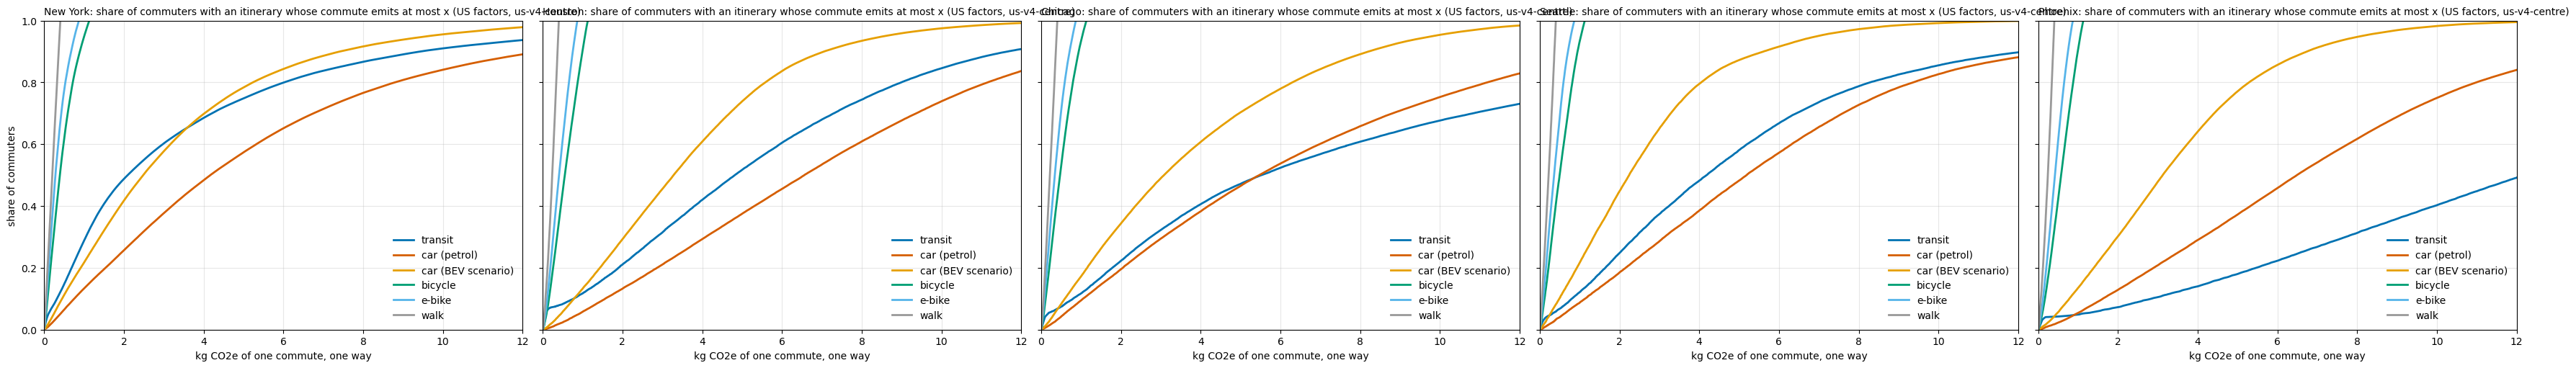

In [8]:
COLOURS = {"transit": "#0072B2", "car": "#D55E00", "car_bev": "#E69F00", "bicycle": "#009E73", "e_bike": "#56B4E9", "walk": "#999999"}
LABELS = {"transit": "transit", "car": "car (petrol)", "car_bev": "car (BEV scenario)", "bicycle": "bicycle", "e_bike": "e-bike", "walk": "walk"}

figure, axes = plt.subplots(ncols=len(AREAS), figsize=(7 * len(AREAS), 5), layout="constrained", sharey=True)
for axis, (area, table) in zip(np.atleast_1d(axes), commutes.items()):
    for mode in REPORTED_MODES:
        rows = table.loc[(table["mode"] == mode) & table["grams"].notna()]
        if rows.empty:
            continue
        order = np.argsort(rows["grams"].to_numpy())
        grams = rows["grams"].to_numpy()[order]
        share = np.cumsum(rows["workers"].to_numpy()[order]) / rows["workers"].sum()
        axis.plot(grams / 1000, share, color=COLOURS[mode], linewidth=2, label=LABELS[mode])
    axis.set_xlim(0, 12)
    axis.set_ylim(0, 1)
    axis.set_xlabel("kg CO2e of one commute, one way")
    axis.set_title(f"{area}: share of commuters with an itinerary whose commute emits at most x (US factors, {RUN_TAG})", loc="left", fontsize=10)
    axis.grid(alpha=0.3)
    axis.legend(loc="lower right", frameon=False)
np.atleast_1d(axes)[0].set_ylabel("share of commuters")
figure.savefig(FIGURES / f"05.10-commute-emissions-{RUN_TAG}-distribution.png", dpi=200, bbox_inches="tight");

## 8. Maps: weekly commuting CO₂e by home tract, New York beside Houston

As in 05.9: one figure per mode, the paper's four weekly classes and colours, the median over the
tract's residents of their weekly commuting CO₂e among the residents with an itinerary; tracts
where fewer than half of the residents have an itinerary are grey. Saved in `figures/` with the
run tag in the name.

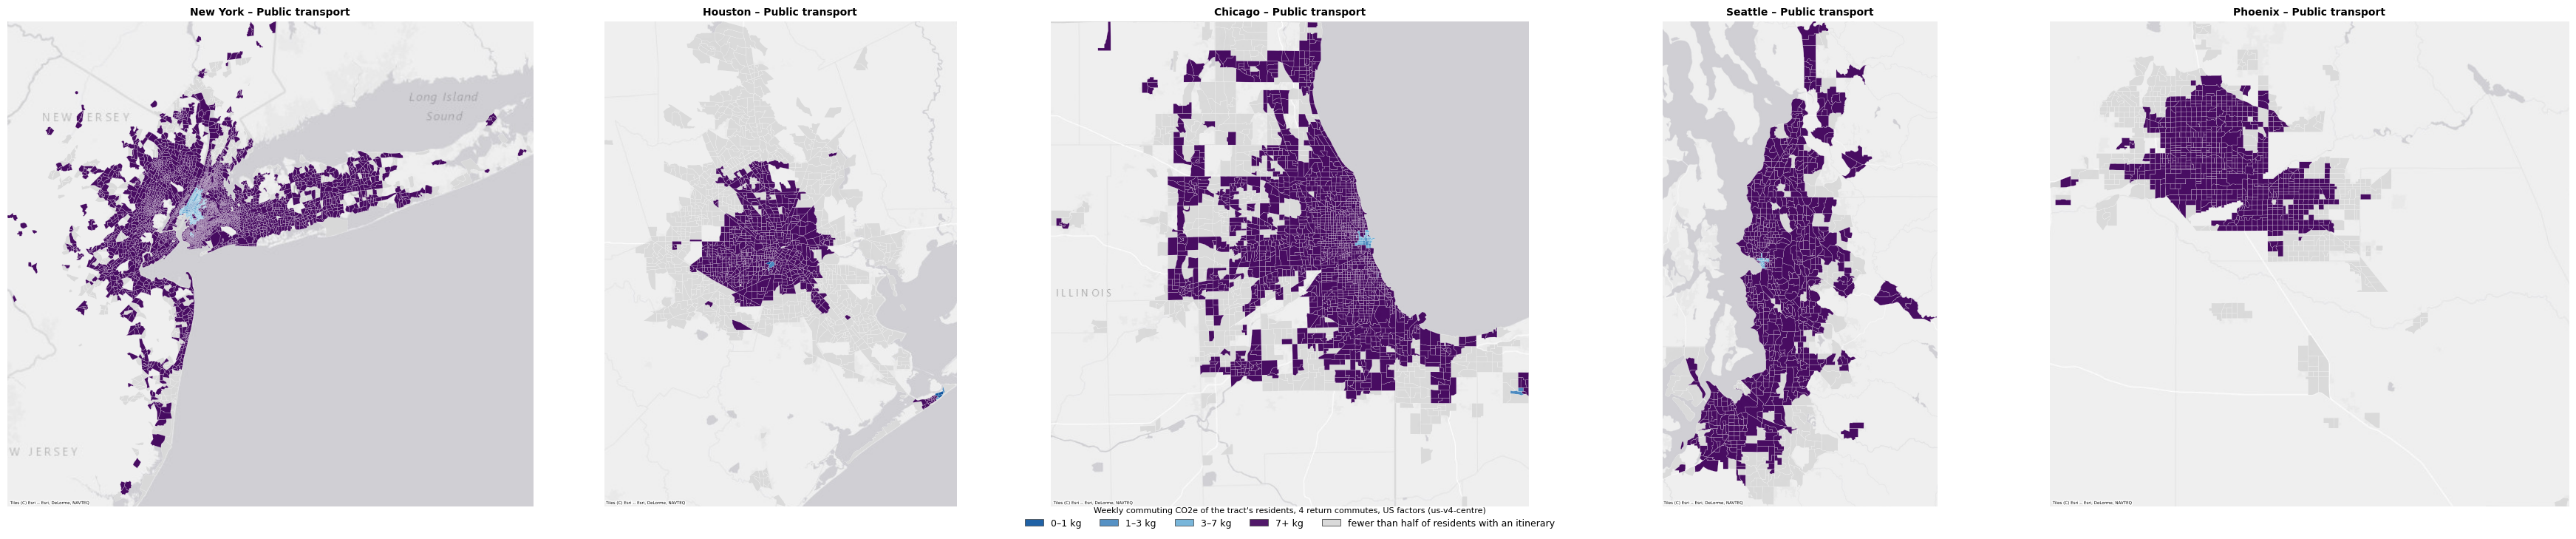

saved figures/05.10-commute-emissions-us-v4-centre-transit.png


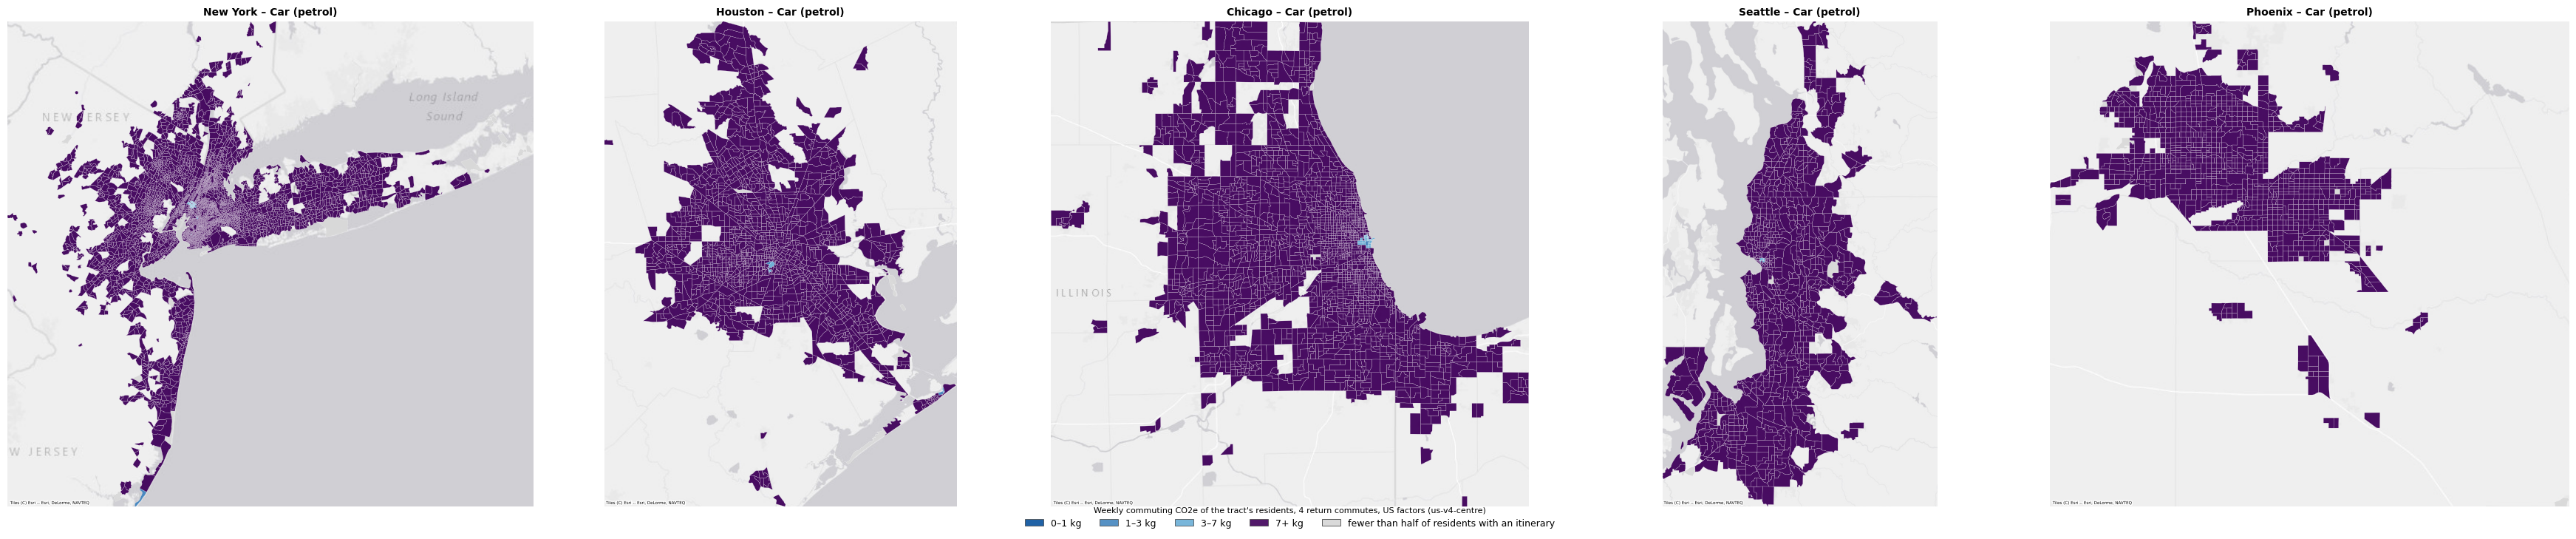

saved figures/05.10-commute-emissions-us-v4-centre-car.png


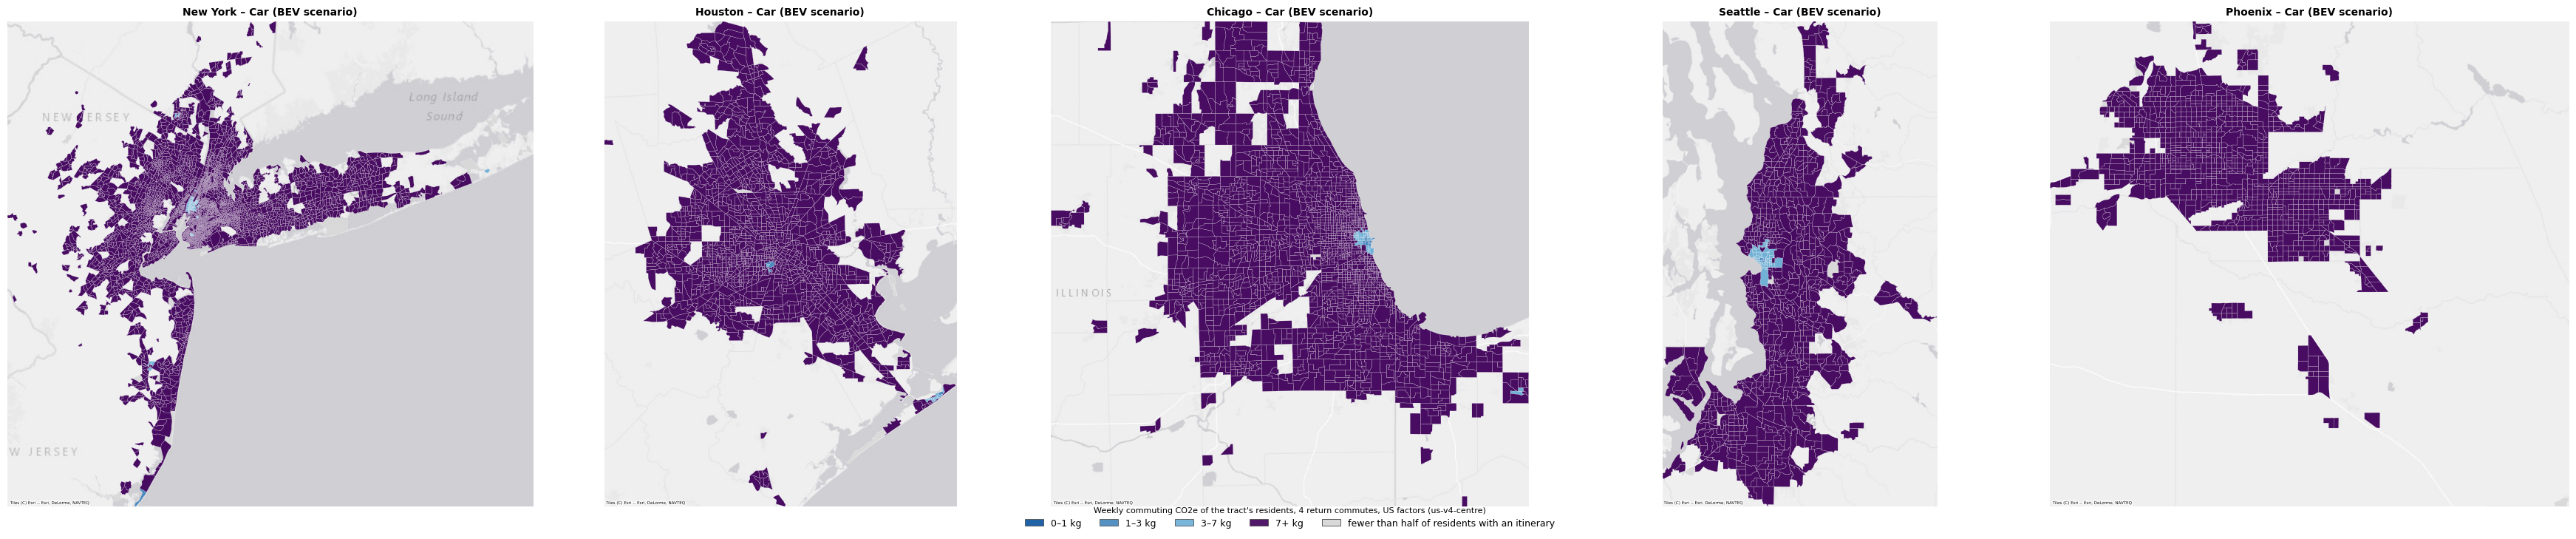

saved figures/05.10-commute-emissions-us-v4-centre-car_bev.png


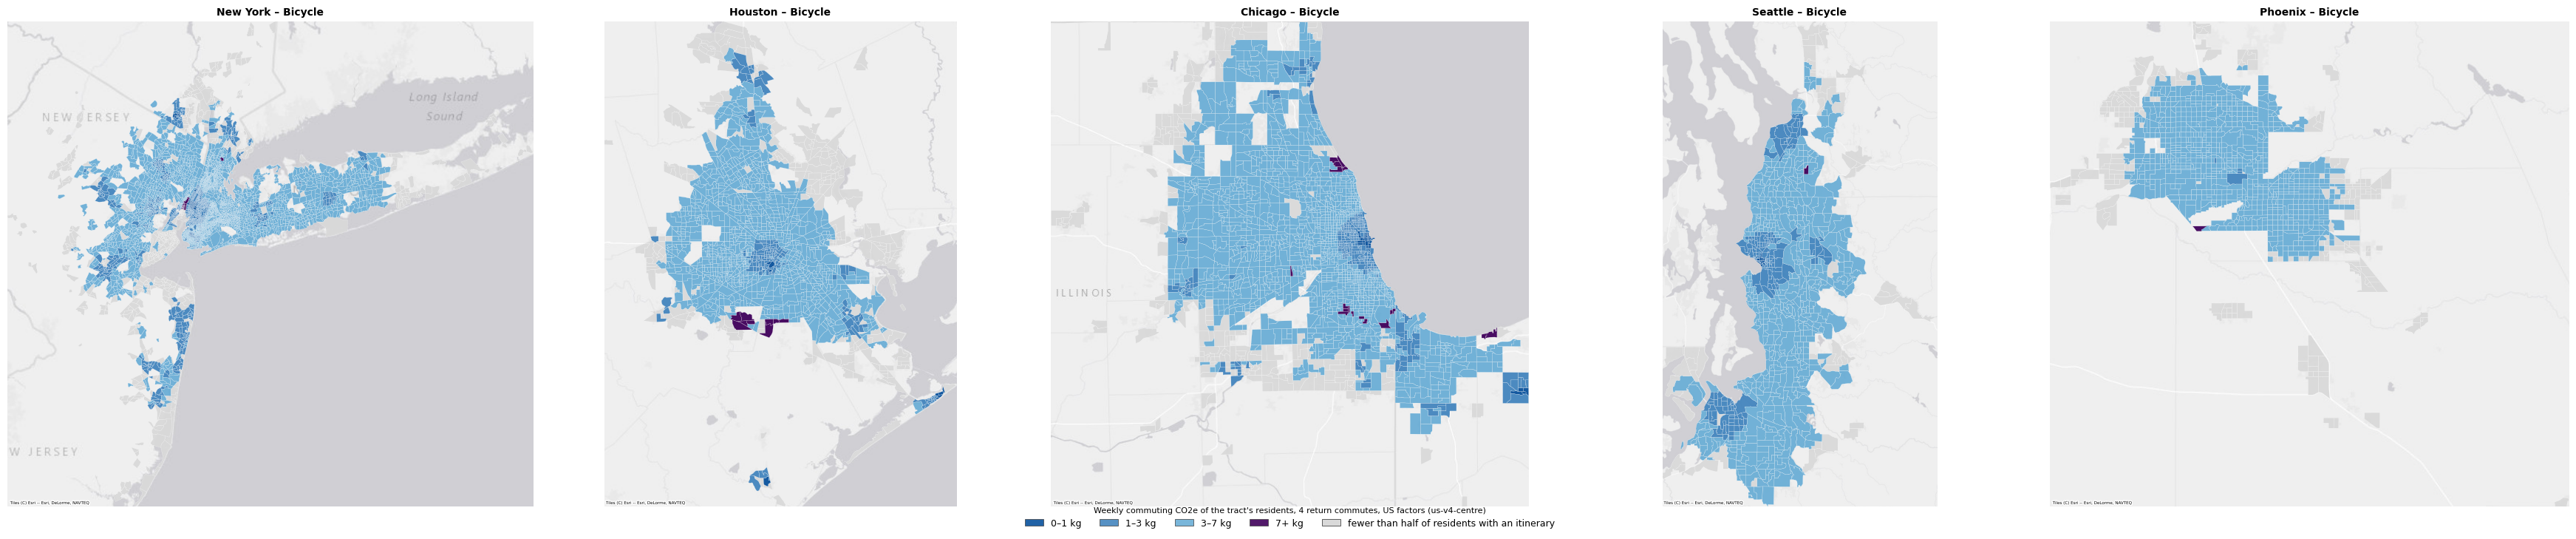

saved figures/05.10-commute-emissions-us-v4-centre-bicycle.png


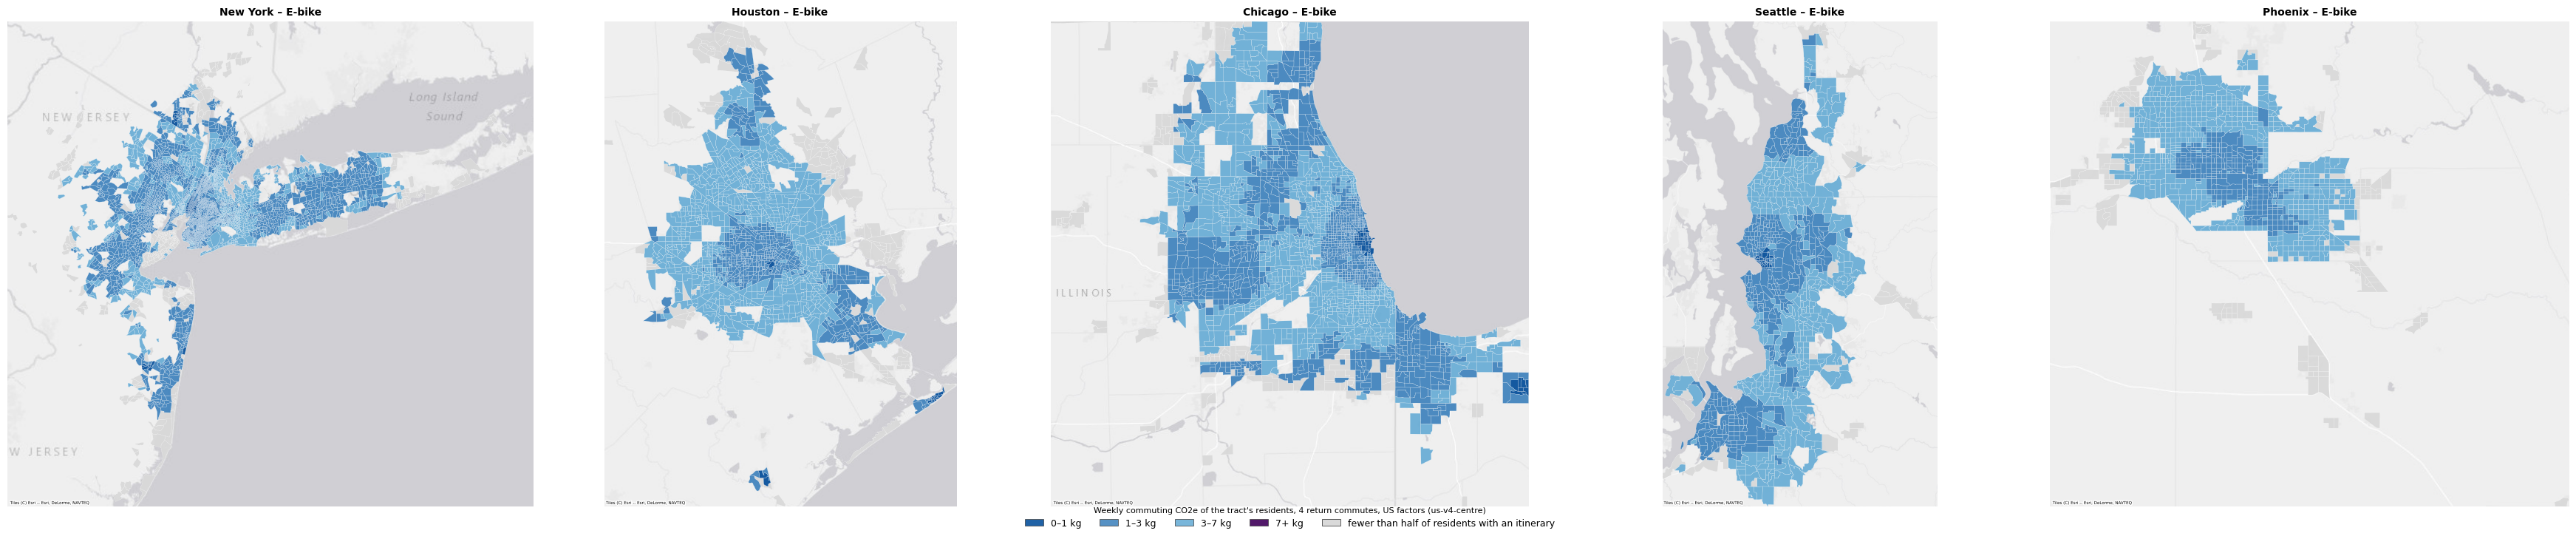

saved figures/05.10-commute-emissions-us-v4-centre-e_bike.png


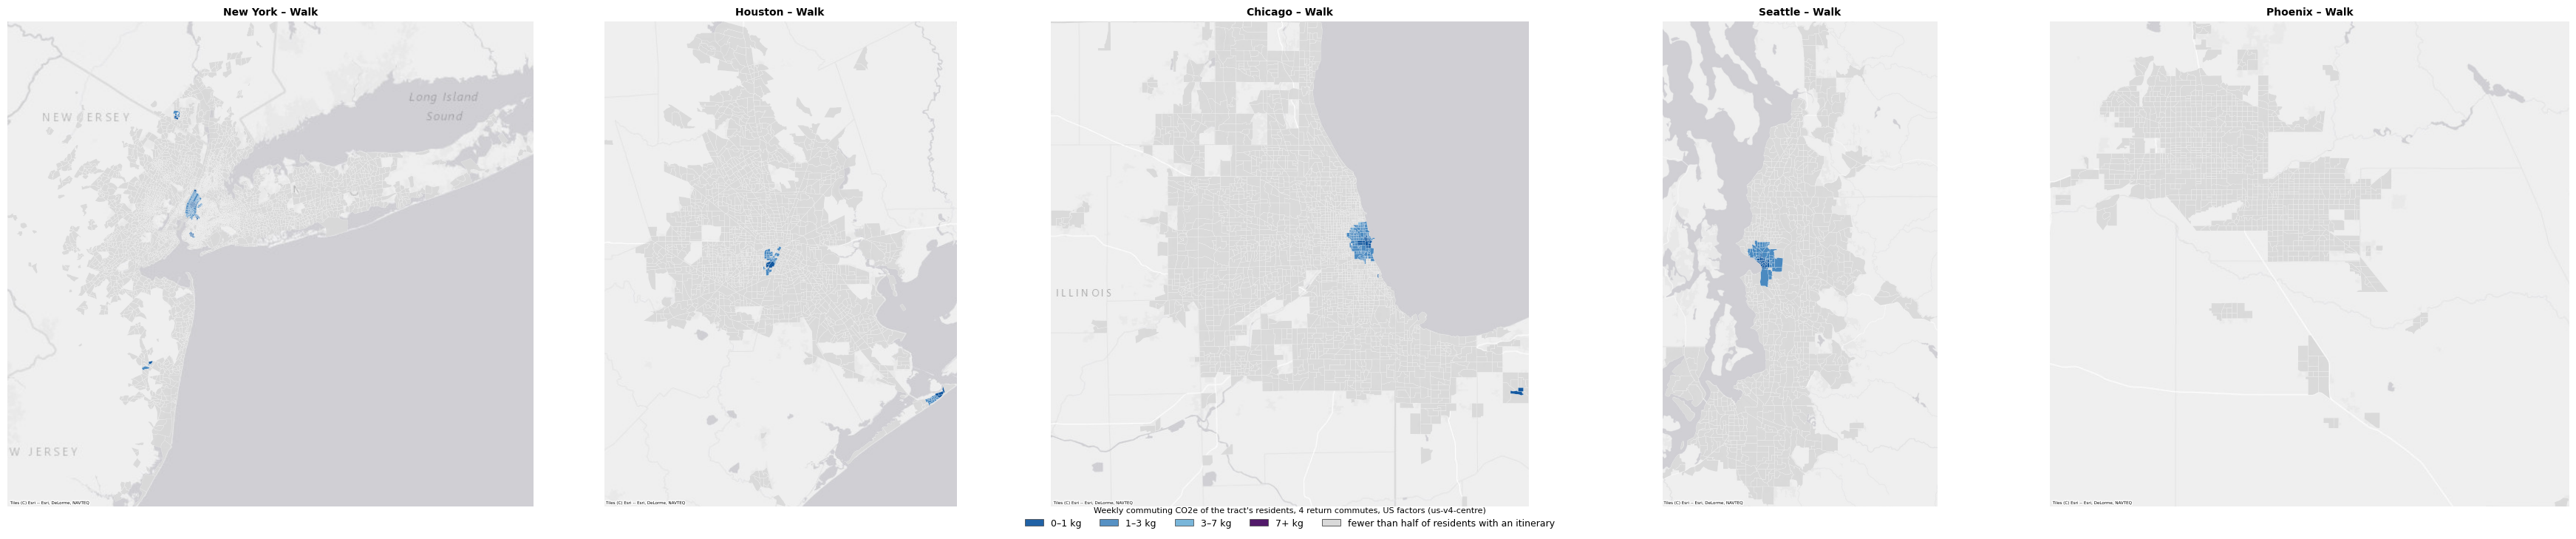

saved figures/05.10-commute-emissions-us-v4-centre-walk.png
home tracts per weekly class:


0–1 kg  1–3 kg  3–7 kg  7+ kg  \
mode    area                                      
transit New York       2      89     384   3776   
        Houston        4       3       1    726   
        Chicago        0      12      24   1697   
        Seattle        0       0      18    662   
        Phoenix        0       0       0    692   
car     New York       0       2      60   4509   
        Houston        0       2       4   1437   
        Chicago        0       2      21   2128   
        Seattle        0       0       5    782   
        Phoenix        0       0       0   1000   
car_bev New York       1      17     156   4397   
        Houston        0       4      12   1427   
        Chicago        0      14      42   2095   
        Seattle        0       5      53    729   
        Phoenix        0       0       0   1000   
bicycle New York      96    1079    2878     18   
        Houston       10     159    1029      9   
        Chicago       36     374    1504     18   
        Seattle       13     179     540      1   
        Phoenix        0       4     795      1   
e_bike  New York     204    2932    1087      0   
        Houston       20     501     777      0   
        Chicago       70    1109     852      0   
        Seattle       37     361     360      0   
        Phoenix        0     268     587      0   
walk    New York      82     193       0      0   
        Houston        8      34       0      0   
        Chicago       20     120       3      0   
        Seattle       25      42       0      0   
        Phoenix        0       0       0      0   

                  fewer than half of residents with an itinerary  
mode    area                                                      
transit New York                                             338  
        Houston                                              713  
        Chicago                                              420  
        Seattle                                              111  
        Phoenix                                              316  
car     New York                                              18  
        Houston                                                4  
        Chicago                                                2  
        Seattle                                                4  
        Phoenix                                                8  
car_bev New York                                              18  
        Houston                                                4  
        Chicago                                                2  
        Seattle                                                4  
        Phoenix                                                8  
bicycle New York                                             518  
        Houston                                              240  
        Chicago                                              221  
        Seattle                                               58  
        Phoenix                                              208  
e_bike  New York                                             366  
        Houston                                              149  
        Chicago                                              122  
        Seattle                                               33  
        Phoenix                                              153  
walk    New York                                            4314  
        Houston                                             1405  
        Chicago                                             2010  
        Seattle                                              724  
        Phoenix                                             1008

In [9]:
import contextily as ctx
import matplotlib.patches as mpatches

BASEMAP = ctx.providers.Esri.WorldGrayCanvas
ctx.set_cache_dir(str(Path.home() / ".cache" / "contextily"))
FIGS_DPI = 300

plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 8,
                     "axes.linewidth": 0.6, "svg.fonttype": "none", "pdf.fonttype": 42})

BINS = [0, 1, 3, 7, np.inf]
BIN_LABELS = ["0–1 kg", "1–3 kg", "3–7 kg", "7+ kg"]
BIN_COLOURS = {"0–1 kg": "#08519C", "1–3 kg": "#4385BE", "3–7 kg": "#6BAED6", "7+ kg": "#3F005A"}
NO_ITINERARY = "fewer than half of residents with an itinerary"
NO_ITINERARY_COLOUR = "#d9d9d9"
MODE_TITLES = {"transit": "Public transport", "car": "Car (petrol)", "car_bev": "Car (BEV scenario)", "bicycle": "Bicycle", "e_bike": "E-bike", "walk": "Walk"}
WEEKLY_PER_GRAM = 2 * PARAMETERS["commutes_per_week"] / 1000


def tract_weekly(table, mode):
    rows = table.loc[table["mode"] == mode]
    residents = rows.groupby("from_id")["workers"].sum()
    reached = rows.loc[rows["grams"].notna()]
    share = reached.groupby("from_id")["workers"].sum().reindex(residents.index, fill_value=0) / residents
    weekly = reached.groupby("from_id").apply(lambda r: weighted_median(r["grams"].to_numpy(), r["workers"].to_numpy()), include_groups=False) * WEEKLY_PER_GRAM
    out = pd.DataFrame({"weekly_kg": weekly.reindex(residents.index), "share_with_itinerary": share})
    out["category"] = pd.cut(out["weekly_kg"], bins=BINS, labels=BIN_LABELS, include_lowest=True).astype(object)
    out.loc[out["share_with_itinerary"] < 0.5, "category"] = NO_ITINERARY
    return out.rename_axis("tract").reset_index()


tract_polygons = {}
for area, spec in AREAS.items():
    polygons = gpd.read_parquet(spec["folder"] / f"tracts-kept-{YEAR}.parquet")[["tract", "geometry"]].to_crs("EPSG:3857")
    polygons["tract"] = polygons["tract"].astype(str)
    tract_polygons[area] = polygons


def draw_panel(axis, area, mode):
    layer = tract_polygons[area].merge(tract_weekly(commutes[area], mode), on="tract", how="left")
    layer["category"] = layer["category"].fillna(NO_ITINERARY)
    for label, colour in [(NO_ITINERARY, NO_ITINERARY_COLOUR)] + list(BIN_COLOURS.items()):
        subset = layer.loc[layer["category"] == label]
        if len(subset):
            subset.plot(ax=axis, color=colour, edgecolor="white", linewidth=0.15, alpha=0.95)
    west, south, east, north = layer.total_bounds
    axis.set_xlim(west, east)
    axis.set_ylim(south, north)
    try:
        ctx.add_basemap(axis, source=BASEMAP, attribution_size=4)
    except Exception as error:
        print(f"{area}, {mode}: basemap not drawn ({type(error).__name__}: {str(error)[:120]})")
    axis.set_xticks([])
    axis.set_yticks([])
    for spine in axis.spines.values():
        spine.set_visible(False)
    axis.set_aspect("equal")
    axis.set_title(f"{area} – {MODE_TITLES[mode]}", fontsize=10, fontweight="bold", pad=6)
    return layer


handles = [mpatches.Patch(facecolor=BIN_COLOURS[label], edgecolor="#444444", linewidth=0.6, alpha=0.9, label=label) for label in BIN_LABELS]
handles.append(mpatches.Patch(facecolor=NO_ITINERARY_COLOUR, edgecolor="#444444", linewidth=0.6, label=NO_ITINERARY))

class_counts = []
for mode in REPORTED_MODES:
    figure, axes = plt.subplots(ncols=len(AREAS), figsize=(7 * len(AREAS), 7))
    for axis, area in zip(np.atleast_1d(axes), AREAS):
        layer = draw_panel(axis, area, mode)
        counts = layer["category"].value_counts()
        class_counts.append({"mode": mode, "area": area, **{label: int(counts.get(label, 0)) for label in BIN_LABELS + [NO_ITINERARY]}})
    figure.legend(handles=handles, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.04), frameon=False, fontsize=9,
                  title=f"Weekly commuting CO2e of the tract's residents, {PARAMETERS['commutes_per_week']} return commutes, US factors ({RUN_TAG})")
    figure.tight_layout()
    png = FIGURES / f"05.10-commute-emissions-{RUN_TAG}-{mode}.png"
    figure.savefig(png, dpi=FIGS_DPI, bbox_inches="tight")
    plt.show()
    plt.close(figure)
    print(f"saved {png}")

print("home tracts per weekly class:")
pd.DataFrame(class_counts).set_index(["mode", "area"])

## Replicating to another city or refining the factors

1. Run 05.1, 05.2, 05.3 and 05.7 for the metro, add it to `AREAS` with its MSA code from
   `car_factors_msa.csv` and its GTFS folder, add its agencies to `AGENCY_CROSSWALK` (the
   coverage table of step 3 lists the GTFS agencies left on the fallback rows and the NTD agencies
   found in no feed), and run this notebook.
2. For a new factor version, bump `RUN_TAG`, which renames the transit and car matrix folders; bump
   `STREET_MATRIX_FOLDER` too only if the bicycle, e-bike or walking rows changed.